In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    from IPython.display import display
except ImportError:
    display = print

plt.style.use("seaborn-v0_8-whitegrid")

DATA_PATH = Path("JUN18.xlsx")

/Users/g.y/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:22: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/Users/g.y/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


In [3]:
# Read and inspect the LAOS worksheet

raw_laos = pd.read_excel(
    DATA_PATH,
    sheet_name="LAOS",
    header=None
)

print("LAOS worksheet shape:", raw_laos.shape)

display(raw_laos.iloc[:10, :12])

LAOS worksheet shape: (2008, 73)


,0,1,2,3,4,5,6,7,8,9,10,11
0,LAOS omega=1; Gamma=0.5,NaN,NaN,NaN,LAOS omega=1; Gamma=1,NaN,NaN,NaN,LAOS omega=1; Gamma=5,NaN,NaN,NaN
1,Step time,Stress,Strain,NaN,Step time,Stress,Strain,NaN,Step time,Stress,Strain,NaN
2,s,Pa,%,NaN,s,Pa,%,NaN,s,Pa,%,NaN
3,0.0202,0.192445,99.3642,NaN,0.020169,0.190733,72.595,NaN,0.02013,0.198781,75.5292,NaN
4,0.040342,0.025037,-0.119629,NaN,0.04031,0.029325,1.35986,NaN,0.040394,0.043447,13.0716,NaN
5,0.060362,0.034674,2.50891,NaN,0.06033,0.033834,4.95942,NaN,0.060291,0.056142,24.5647,NaN
6,0.080381,0.02816,3.45034,NaN,0.08035,0.031396,6.90188,NaN,0.080311,0.045971,34.5143,NaN
7,0.100279,0.014168,4.45037,NaN,0.100369,0.020191,8.90057,NaN,0.10033,0.037292,44.5037,NaN
8,0.120542,0.018803,5.44741,NaN,0.120511,0.0171,10.8951,NaN,0.120472,0.044127,54.4755,NaN
9,0.14044,0.00809,6.44244,NaN,0.14053,0.016518,12.8852,NaN,0.140491,0.034235,64.4258,NaN


In [4]:
# Reshape the LAOS data

laos_blocks = []

for start_column in range(0, 68, 4):
    condition_name = str(
        raw_laos.iloc[0, start_column]
    ).strip()

    condition_data = raw_laos.iloc[
        3:,
        [
            start_column,
            start_column + 1,
            start_column + 2
        ]
    ].copy()

    condition_data.columns = [
        "time_s",
        "stress_pa",
        "strain_pct"
    ]

    condition_data = condition_data.apply(
        pd.to_numeric,
        errors="coerce"
    )

    condition_data = condition_data.dropna(
        subset=[
            "time_s",
            "stress_pa",
            "strain_pct"
        ]
    ).reset_index(drop=True)

    condition_data.insert(
        0,
        "condition",
        condition_name
    )

    laos_blocks.append(condition_data)


laos_data = pd.concat(
    laos_blocks,
    ignore_index=True
)

print(
    "Number of LAOS conditions:",
    laos_data["condition"].nunique()
)

print(
    "Total number of measurements:",
    len(laos_data)
)

display(laos_data.head(10))

Number of LAOS conditions: 17
Total number of measurements: 33986


,condition,time_s,stress_pa,strain_pct
0,LAOS omega=1; Gamma=0.5,0.020200,0.192445,99.364200
1,LAOS omega=1; Gamma=0.5,0.040342,0.025037,-0.119629
2,LAOS omega=1; Gamma=0.5,0.060362,0.034674,2.508910
3,LAOS omega=1; Gamma=0.5,0.080381,0.028160,3.450340
4,LAOS omega=1; Gamma=0.5,0.100279,0.014168,4.450370
5,LAOS omega=1; Gamma=0.5,0.120542,0.018803,5.447410
6,LAOS omega=1; Gamma=0.5,0.140440,0.008090,6.442440
7,LAOS omega=1; Gamma=0.5,0.160459,0.004420,7.434580
8,LAOS omega=1; Gamma=0.5,0.180479,0.012595,8.424030
9,LAOS omega=1; Gamma=0.5,0.200498,0.001961,9.410270


In [5]:
# Check the LAOS sampling intervals

sampling_results = []

for condition_name, condition_data in laos_data.groupby(
    "condition",
    sort=False
):
    condition_data = condition_data.sort_values(
        "time_s"
    )

    time_values = condition_data[
        "time_s"
    ].to_numpy()

    time_intervals = np.diff(time_values)

    median_interval = np.median(time_intervals)

    interval_ratio = (
        time_intervals.max()
        / time_intervals.min()
    )

    sampling_results.append(
        {
            "condition": condition_name,
            "number_of_points": len(time_values),
            "duration_s": (
                time_values[-1] - time_values[0]
            ),
            "minimum_dt_s": time_intervals.min(),
            "median_dt_s": median_interval,
            "maximum_dt_s": time_intervals.max(),
            "estimated_sampling_frequency_hz": (
                1 / median_interval
            ),
            "maximum_minimum_dt_ratio": interval_ratio,
            "approximately_uniform": (
                interval_ratio < 1.05
            )
        }
    )


sampling_summary = pd.DataFrame(
    sampling_results
)

display(
    sampling_summary.round(
        {
            "duration_s": 3,
            "minimum_dt_s": 6,
            "median_dt_s": 6,
            "maximum_dt_s": 6,
            "estimated_sampling_frequency_hz": 3,
            "maximum_minimum_dt_ratio": 4
        }
    )
)

,condition,number_of_points,duration_s,minimum_dt_s,median_dt_s,maximum_dt_s,estimated_sampling_frequency_hz,maximum_minimum_dt_ratio,approximately_uniform
0,LAOS omega=1; Gamma=0.5,1996,39.975,0.0198,0.02,0.0203,50.0,1.0253,True
1,LAOS omega=1; Gamma=1,1996,39.975,0.0198,0.02,0.0203,50.0,1.0253,True
2,LAOS omega=1; Gamma=5,1996,39.975,0.0198,0.02,0.0203,50.0,1.0253,True
3,LAOS omega=1; Gamma=10,1996,39.975,0.0198,0.02,0.0203,50.0,1.0253,True
4,LAOS omega=1; Gamma=50,1996,39.975,0.0197,0.02,0.0203,50.0,1.0305,True
5,LAOS omega=1; Gamma=100,1996,39.975,0.0197,0.02,0.0203,50.0,1.0305,True
6,LAOS omega=5 Gamma=0.5,2005,39.963,0.0197,0.02,0.0201,50.0,1.0203,True
7,LAOS omega=5 Gamma=1.0,2005,39.963,0.0197,0.02,0.0201,50.0,1.0203,True
8,LAOS omega=5 Gamma=5,2005,39.963,0.0197,0.02,0.0201,50.0,1.0203,True
9,LAOS omega=5 Gamma=10,2005,39.963,0.0197,0.02,0.0201,50.0,1.0203,True


In [6]:
# Extract the experimental parameters

import re

parameter_values = laos_data[
    "condition"
].str.extract(
    r"omega\s*=\s*([0-9.]+).*Gamma\s*=\s*([0-9.]+)",
    flags=re.IGNORECASE
)

laos_data["omega_rad_s"] = pd.to_numeric(
    parameter_values[0]
)

laos_data["strain_amplitude"] = pd.to_numeric(
    parameter_values[1]
)

laos_data["fundamental_frequency_hz"] = (
    laos_data["omega_rad_s"]
    / (2 * np.pi)
)


condition_parameters = (
    laos_data[
        [
            "condition",
            "omega_rad_s",
            "strain_amplitude",
            "fundamental_frequency_hz"
        ]
    ]
    .drop_duplicates()
    .sort_values(
        [
            "omega_rad_s",
            "strain_amplitude"
        ]
    )
    .reset_index(drop=True)
)

display(
    condition_parameters.round(
        {
            "omega_rad_s": 2,
            "strain_amplitude": 2,
            "fundamental_frequency_hz": 4
        }
    )
)

,condition,omega_rad_s,strain_amplitude,fundamental_frequency_hz
0,LAOS omega=0.5 Gamma=1,0.5,1.0,0.0796
1,LAOS omega=0.5 Gamma=5,0.5,5.0,0.0796
2,LAOS omega=0.5 Gamma=10,0.5,10.0,0.0796
3,LAOS omega=0.5 Gamma=50,0.5,50.0,0.0796
4,LAOS omega=0.5 Gamma=100,0.5,100.0,0.0796
5,LAOS omega=1; Gamma=0.5,1.0,0.5,0.1592
6,LAOS omega=1; Gamma=1,1.0,1.0,0.1592
7,LAOS omega=1; Gamma=5,1.0,5.0,0.1592
8,LAOS omega=1; Gamma=10,1.0,10.0,0.1592
9,LAOS omega=1; Gamma=50,1.0,50.0,0.1592


Condition: LAOS omega=1; Gamma=10
Number of points: 1996
Expected oscillation period: 6.283 s


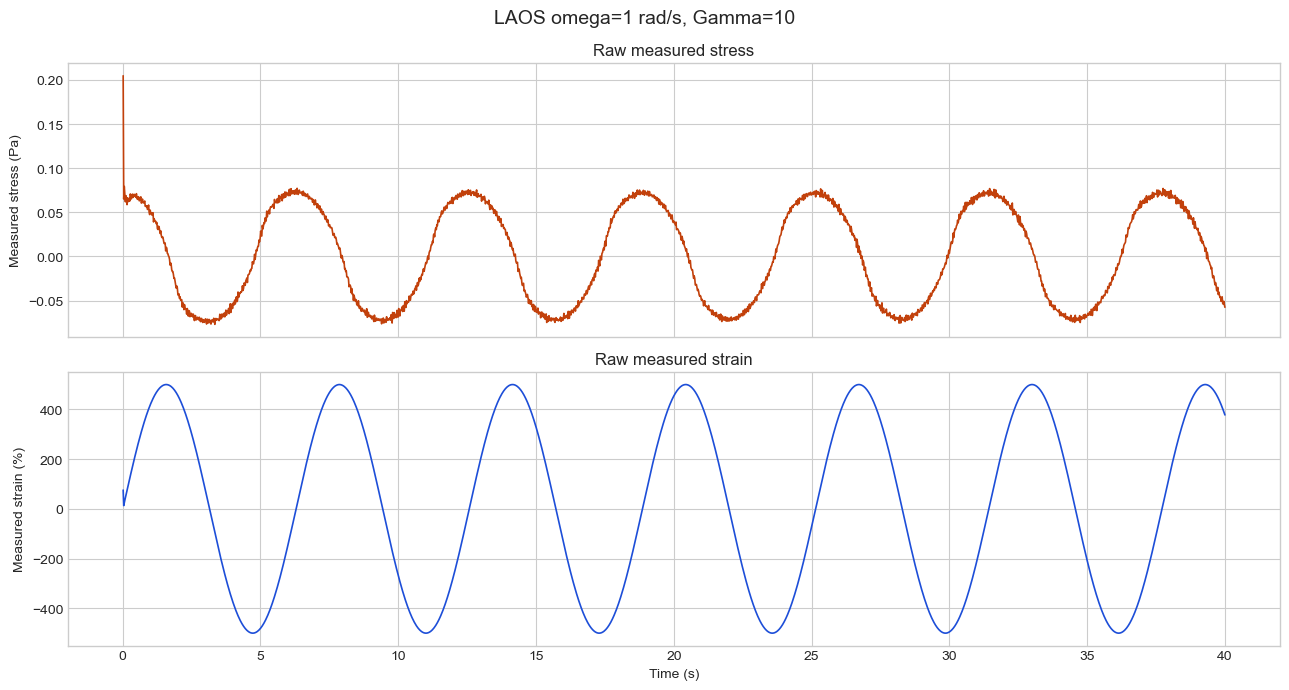

In [7]:
# Plot one raw LAOS experiment

selected_omega = 1.0
selected_strain_amplitude = 10.0

selected_signal = laos_data[
    np.isclose(
        laos_data["omega_rad_s"],
        selected_omega
    )
    &
    np.isclose(
        laos_data["strain_amplitude"],
        selected_strain_amplitude
    )
].sort_values("time_s").reset_index(drop=True)


if selected_signal.empty:
    raise ValueError(
        "The selected LAOS condition was not found."
    )


expected_period_s = (
    2 * np.pi / selected_omega
)

print(
    "Condition:",
    selected_signal["condition"].iloc[0]
)

print(
    "Number of points:",
    len(selected_signal)
)

print(
    f"Expected oscillation period: "
    f"{expected_period_s:.3f} s"
)


fig, axes = plt.subplots(
    2,
    1,
    figsize=(13, 7),
    sharex=True
)

axes[0].plot(
    selected_signal["time_s"],
    selected_signal["stress_pa"],
    color="#C2410C",
    linewidth=1.2
)

axes[0].set_ylabel(
    "Measured stress (Pa)"
)

axes[0].set_title(
    "Raw measured stress"
)


axes[1].plot(
    selected_signal["time_s"],
    selected_signal["strain_pct"],
    color="#1D4ED8",
    linewidth=1.2
)

axes[1].set_xlabel(
    "Time (s)"
)

axes[1].set_ylabel(
    "Measured strain (%)"
)

axes[1].set_title(
    "Raw measured strain"
)


fig.suptitle(
    "LAOS omega=1 rad/s, Gamma=10",
    fontsize=14
)

fig.tight_layout()

plt.show()

Detected strain peaks: 6
Peak times: [ 1.583  7.875 14.147 20.438 26.71  33.002]
Analysis start time: 7.875 s
Analysis end time: 33.002 s
Number of complete cycles: 4
Number of selected points: 1255


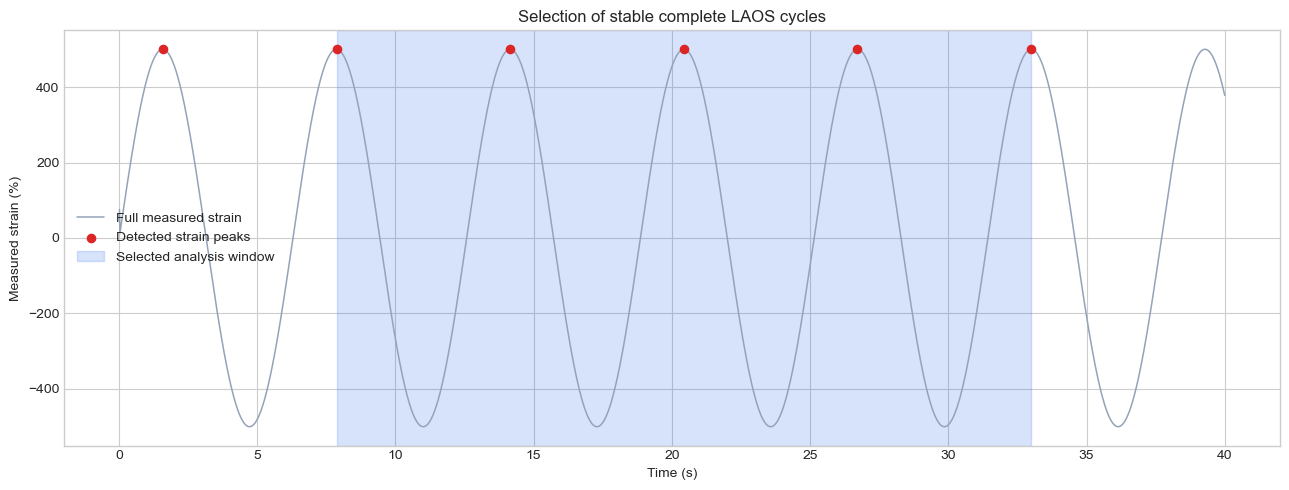

In [8]:
# Select stable complete oscillation cycles

from scipy.signal import find_peaks

time_values = selected_signal[
    "time_s"
].to_numpy()

strain_values = selected_signal[
    "strain_pct"
].to_numpy()

median_dt = np.median(
    np.diff(time_values)
)

minimum_peak_distance = int(
    0.8 * expected_period_s / median_dt
)

peak_indices, peak_properties = find_peaks(
    strain_values,
    distance=minimum_peak_distance,
    prominence=0.5 * np.std(strain_values)
)

peak_times = time_values[
    peak_indices
]

print(
    "Detected strain peaks:",
    len(peak_indices)
)

print(
    "Peak times:",
    np.round(peak_times, 3)
)


if len(peak_indices) < 5:
    raise ValueError(
        "Not enough complete oscillation cycles were detected."
    )


start_peak_index = peak_indices[1]

end_peak_position = min(
    5,
    len(peak_indices) - 1
)

end_peak_index = peak_indices[
    end_peak_position
]


analysis_signal = selected_signal.iloc[
    start_peak_index:end_peak_index + 1
].copy()

analysis_signal["analysis_time_s"] = (
    analysis_signal["time_s"]
    - analysis_signal["time_s"].iloc[0]
)


number_of_cycles = (
    end_peak_position - 1
)

print(
    f"Analysis start time: "
    f"{analysis_signal['time_s'].iloc[0]:.3f} s"
)

print(
    f"Analysis end time: "
    f"{analysis_signal['time_s'].iloc[-1]:.3f} s"
)

print(
    "Number of complete cycles:",
    number_of_cycles
)

print(
    "Number of selected points:",
    len(analysis_signal)
)


fig, axis = plt.subplots(
    figsize=(13, 5)
)

axis.plot(
    selected_signal["time_s"],
    selected_signal["strain_pct"],
    color="#94A3B8",
    linewidth=1.1,
    label="Full measured strain"
)

axis.scatter(
    peak_times,
    strain_values[peak_indices],
    color="#DC2626",
    s=35,
    zorder=3,
    label="Detected strain peaks"
)

axis.axvspan(
    analysis_signal["time_s"].iloc[0],
    analysis_signal["time_s"].iloc[-1],
    color="#2563EB",
    alpha=0.18,
    label="Selected analysis window"
)

axis.set_xlabel("Time (s)")
axis.set_ylabel("Measured strain (%)")

axis.set_title(
    "Selection of stable complete LAOS cycles"
)

axis.legend()

fig.tight_layout()

plt.show()

Number of uniform points: 1254
Uniform sampling interval: 0.020038 s
Sampling frequency: 49.906 Hz
Nyquist frequency: 24.953 Hz
Maximum time adjustment: 0.000200 s
Strictly uniform: True


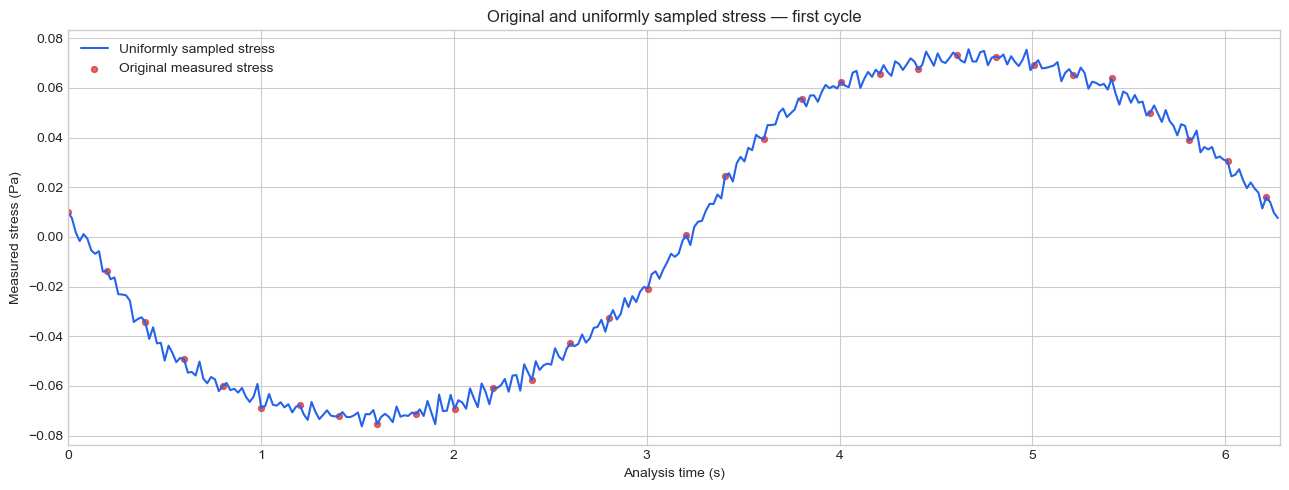

In [9]:
# Create a strictly uniform time grid

original_time_s = analysis_signal[
    "time_s"
].to_numpy()

original_stress_pa = analysis_signal[
    "stress_pa"
].to_numpy()

original_strain_pct = analysis_signal[
    "strain_pct"
].to_numpy()


number_of_uniform_points = (
    len(original_time_s) - 1
)

uniform_time_absolute_s = np.linspace(
    original_time_s[0],
    original_time_s[-1],
    num=number_of_uniform_points,
    endpoint=False
)


uniform_stress_pa = np.interp(
    uniform_time_absolute_s,
    original_time_s,
    original_stress_pa
)

uniform_strain_pct = np.interp(
    uniform_time_absolute_s,
    original_time_s,
    original_strain_pct
)


uniform_signal = pd.DataFrame(
    {
        "time_s": (
            uniform_time_absolute_s
            - uniform_time_absolute_s[0]
        ),
        "stress_pa": uniform_stress_pa,
        "strain_pct": uniform_strain_pct
    }
)


uniform_dt_s = np.diff(
    uniform_signal["time_s"]
)

sampling_interval_s = uniform_dt_s[0]

sampling_frequency_hz = (
    1 / sampling_interval_s
)

nyquist_frequency_hz = (
    sampling_frequency_hz / 2
)


maximum_time_adjustment_s = np.max(
    np.abs(
        uniform_time_absolute_s
        - original_time_s[:-1]
    )
)


print(
    "Number of uniform points:",
    len(uniform_signal)
)

print(
    f"Uniform sampling interval: "
    f"{sampling_interval_s:.6f} s"
)

print(
    f"Sampling frequency: "
    f"{sampling_frequency_hz:.3f} Hz"
)

print(
    f"Nyquist frequency: "
    f"{nyquist_frequency_hz:.3f} Hz"
)

print(
    f"Maximum time adjustment: "
    f"{maximum_time_adjustment_s:.6f} s"
)

print(
    "Strictly uniform:",
    np.allclose(
        uniform_dt_s,
        sampling_interval_s
    )
)


fig, axis = plt.subplots(
    figsize=(13, 5)
)

first_cycle_mask = (
    uniform_signal["time_s"]
    <= expected_period_s
)

axis.plot(
    uniform_signal.loc[
        first_cycle_mask,
        "time_s"
    ],
    uniform_signal.loc[
        first_cycle_mask,
        "stress_pa"
    ],
    color="#2563EB",
    linewidth=1.5,
    label="Uniformly sampled stress"
)

axis.scatter(
    analysis_signal[
        "analysis_time_s"
    ].iloc[:-1:10],
    analysis_signal[
        "stress_pa"
    ].iloc[:-1:10],
    color="#DC2626",
    s=18,
    alpha=0.7,
    label="Original measured stress"
)

axis.set_xlim(
    0,
    expected_period_s
)

axis.set_xlabel(
    "Analysis time (s)"
)

axis.set_ylabel(
    "Measured stress (Pa)"
)

axis.set_title(
    "Original and uniformly sampled stress — first cycle"
)

axis.legend()

fig.tight_layout()

plt.show()

Frequency resolution: 0.0398 Hz
Expected fundamental frequency: 0.1592 Hz
Closest FFT frequency bin: 0.1592 Hz


,harmonic_order,target_frequency_hz,fft_bin_frequency_hz,stress_amplitude_pa,stress_relative_to_fundamental_pct,strain_amplitude_pct,strain_relative_to_fundamental_pct
0,1,0.1592,0.1592,0.076466,100.000,500.046381,100.000
1,2,0.3183,0.3184,0.000054,0.070,0.073723,0.015
2,3,0.4775,0.4776,0.006221,8.136,0.028320,0.006
3,4,0.6366,0.6368,0.000018,0.024,0.014777,0.003
4,5,0.7958,0.7959,0.002282,2.984,0.008436,0.002
5,6,0.9549,0.9551,0.000008,0.010,0.006549,0.001
6,7,1.1141,1.1143,0.000937,1.226,0.005616,0.001
7,8,1.2732,1.2735,0.000009,0.012,0.003118,0.001
8,9,1.4324,1.4327,0.000381,0.499,0.002386,0.000


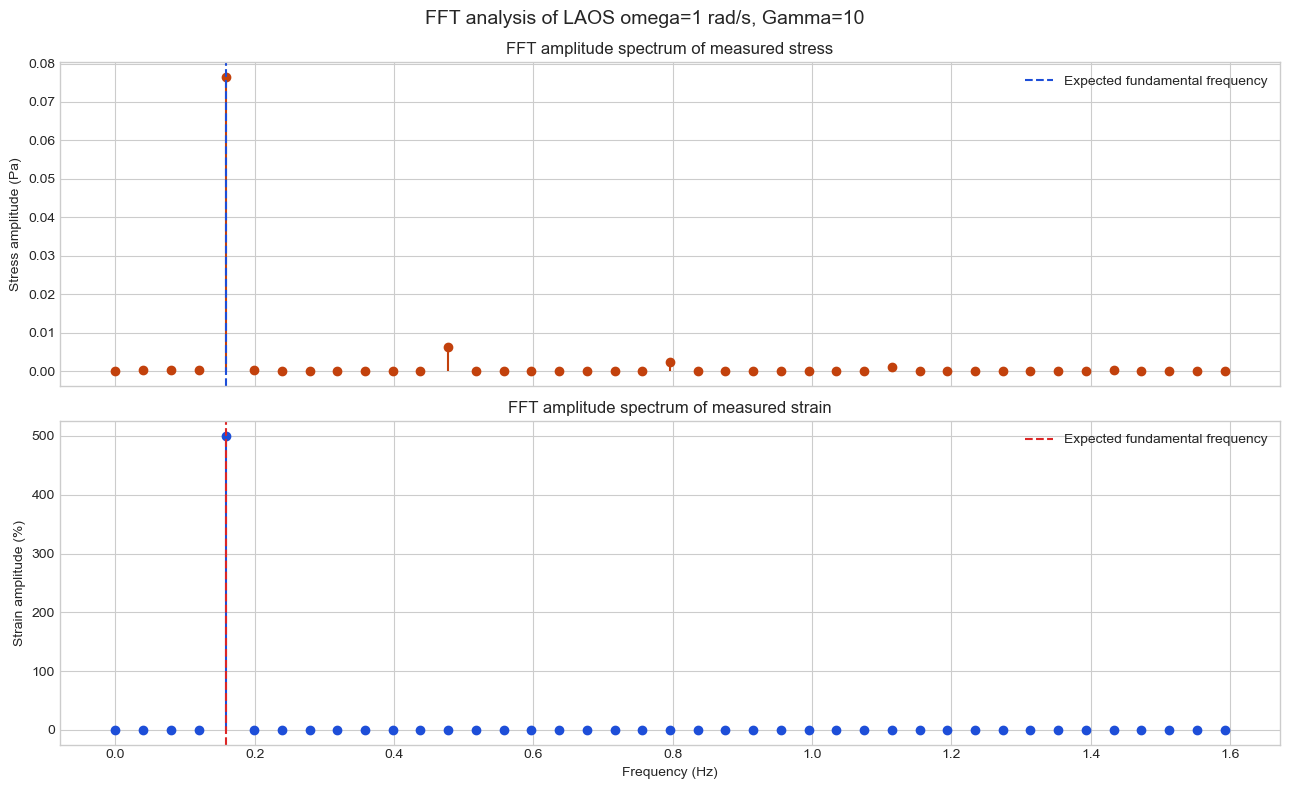

In [10]:
# Apply FFT to measured stress and strain

number_of_samples = len(
    uniform_signal
)

stress_centered = (
    uniform_signal["stress_pa"].to_numpy()
    - uniform_signal["stress_pa"].mean()
)

strain_centered = (
    uniform_signal["strain_pct"].to_numpy()
    - uniform_signal["strain_pct"].mean()
)


frequency_hz = np.fft.rfftfreq(
    number_of_samples,
    d=sampling_interval_s
)


def calculate_single_sided_amplitude(signal_values):
    fft_values = np.fft.rfft(
        signal_values
    )

    amplitude = (
        np.abs(fft_values)
        / number_of_samples
    )

    if number_of_samples % 2 == 0:
        amplitude[1:-1] *= 2
    else:
        amplitude[1:] *= 2

    return amplitude


stress_amplitude_pa = (
    calculate_single_sided_amplitude(
        stress_centered
    )
)

strain_amplitude_pct = (
    calculate_single_sided_amplitude(
        strain_centered
    )
)


expected_fundamental_hz = (
    selected_omega / (2 * np.pi)
)

frequency_resolution_hz = (
    frequency_hz[1] - frequency_hz[0]
)


fundamental_index = np.argmin(
    np.abs(
        frequency_hz
        - expected_fundamental_hz
    )
)

detected_fundamental_hz = (
    frequency_hz[fundamental_index]
)


print(
    f"Frequency resolution: "
    f"{frequency_resolution_hz:.4f} Hz"
)

print(
    f"Expected fundamental frequency: "
    f"{expected_fundamental_hz:.4f} Hz"
)

print(
    f"Closest FFT frequency bin: "
    f"{detected_fundamental_hz:.4f} Hz"
)


harmonic_rows = []

stress_fundamental_amplitude = (
    stress_amplitude_pa[fundamental_index]
)

strain_fundamental_amplitude = (
    strain_amplitude_pct[fundamental_index]
)


for harmonic_order in range(1, 10):
    target_frequency_hz = (
        harmonic_order
        * expected_fundamental_hz
    )

    harmonic_index = np.argmin(
        np.abs(
            frequency_hz
            - target_frequency_hz
        )
    )

    harmonic_rows.append(
        {
            "harmonic_order": harmonic_order,
            "target_frequency_hz": target_frequency_hz,
            "fft_bin_frequency_hz": frequency_hz[
                harmonic_index
            ],
            "stress_amplitude_pa": stress_amplitude_pa[
                harmonic_index
            ],
            "stress_relative_to_fundamental_pct": (
                stress_amplitude_pa[harmonic_index]
                / stress_fundamental_amplitude
                * 100
            ),
            "strain_amplitude_pct": strain_amplitude_pct[
                harmonic_index
            ],
            "strain_relative_to_fundamental_pct": (
                strain_amplitude_pct[harmonic_index]
                / strain_fundamental_amplitude
                * 100
            )
        }
    )


harmonic_table = pd.DataFrame(
    harmonic_rows
)

display(
    harmonic_table.round(
        {
            "target_frequency_hz": 4,
            "fft_bin_frequency_hz": 4,
            "stress_amplitude_pa": 6,
            "stress_relative_to_fundamental_pct": 3,
            "strain_amplitude_pct": 6,
            "strain_relative_to_fundamental_pct": 3
        }
    )
)


maximum_plot_frequency_hz = 1.6

plot_mask = (
    frequency_hz
    <= maximum_plot_frequency_hz
)


fig, axes = plt.subplots(
    2,
    1,
    figsize=(13, 8),
    sharex=True
)


axes[0].stem(
    frequency_hz[plot_mask],
    stress_amplitude_pa[plot_mask],
    linefmt="#C2410C",
    markerfmt="o",
    basefmt=" "
)

axes[0].axvline(
    expected_fundamental_hz,
    color="#1D4ED8",
    linestyle="--",
    label="Expected fundamental frequency"
)

axes[0].set_ylabel(
    "Stress amplitude (Pa)"
)

axes[0].set_title(
    "FFT amplitude spectrum of measured stress"
)

axes[0].legend()


axes[1].stem(
    frequency_hz[plot_mask],
    strain_amplitude_pct[plot_mask],
    linefmt="#1D4ED8",
    markerfmt="o",
    basefmt=" "
)

axes[1].axvline(
    expected_fundamental_hz,
    color="#DC2626",
    linestyle="--",
    label="Expected fundamental frequency"
)

axes[1].set_xlabel(
    "Frequency (Hz)"
)

axes[1].set_ylabel(
    "Strain amplitude (%)"
)

axes[1].set_title(
    "FFT amplitude spectrum of measured strain"
)

axes[1].legend()


fig.suptitle(
    "FFT analysis of LAOS omega=1 rad/s, Gamma=10",
    fontsize=14
)

fig.tight_layout()

plt.show()

In [11]:
# Calculate harmonic nonlinearity metrics

def calculate_harmonic_metrics(
    harmonic_amplitudes
):
    harmonic_amplitudes = np.asarray(
        harmonic_amplitudes,
        dtype=float
    )

    fundamental_amplitude = (
        harmonic_amplitudes[0]
    )

    higher_harmonics = (
        harmonic_amplitudes[1:]
    )

    odd_higher_harmonics = (
        harmonic_amplitudes[
            [2, 4, 6, 8]
        ]
    )

    even_higher_harmonics = (
        harmonic_amplitudes[
            [1, 3, 5, 7]
        ]
    )

    return {
        "fundamental_amplitude": fundamental_amplitude,
        "I3_I1_pct": (
            harmonic_amplitudes[2]
            / fundamental_amplitude
            * 100
        ),
        "I5_I1_pct": (
            harmonic_amplitudes[4]
            / fundamental_amplitude
            * 100
        ),
        "THD_2_to_9_pct": (
            np.sqrt(
                np.sum(
                    higher_harmonics ** 2
                )
            )
            / fundamental_amplitude
            * 100
        ),
        "odd_higher_harmonic_ratio_pct": (
            np.sqrt(
                np.sum(
                    odd_higher_harmonics ** 2
                )
            )
            / fundamental_amplitude
            * 100
        ),
        "even_higher_harmonic_ratio_pct": (
            np.sqrt(
                np.sum(
                    even_higher_harmonics ** 2
                )
            )
            / fundamental_amplitude
            * 100
        )
    }


stress_metrics = calculate_harmonic_metrics(
    harmonic_table[
        "stress_amplitude_pa"
    ]
)

strain_metrics = calculate_harmonic_metrics(
    harmonic_table[
        "strain_amplitude_pct"
    ]
)


nonlinearity_metrics = pd.DataFrame(
    [
        {
            "signal": "Measured stress",
            "amplitude_unit": "Pa",
            **stress_metrics
        },
        {
            "signal": "Measured strain",
            "amplitude_unit": "%",
            **strain_metrics
        }
    ]
)


display(
    nonlinearity_metrics.round(
        {
            "fundamental_amplitude": 6,
            "I3_I1_pct": 3,
            "I5_I1_pct": 3,
            "THD_2_to_9_pct": 3,
            "odd_higher_harmonic_ratio_pct": 3,
            "even_higher_harmonic_ratio_pct": 3
        }
    )
)

,signal,amplitude_unit,fundamental_amplitude,I3_I1_pct,I5_I1_pct,THD_2_to_9_pct,odd_higher_harmonic_ratio_pct,even_higher_harmonic_ratio_pct
0,Measured stress,Pa,0.076466,8.136,2.984,8.766,8.766,0.076
1,Measured strain,%,500.046381,0.006,0.002,0.016,0.006,0.015


In [12]:
# Apply FFT to all LAOS conditions

def calculate_fft_amplitude(
    signal_values
):
    signal_values = np.asarray(
        signal_values,
        dtype=float
    )

    centered_signal = (
        signal_values
        - signal_values.mean()
    )

    sample_count = len(
        centered_signal
    )

    fft_values = np.fft.rfft(
        centered_signal
    )

    amplitude = (
        np.abs(fft_values)
        / sample_count
    )

    if sample_count % 2 == 0:
        amplitude[1:-1] *= 2
    else:
        amplitude[1:] *= 2

    return amplitude


def analyze_one_laos_condition(
    condition_data
):
    condition_data = (
        condition_data
        .sort_values("time_s")
        .reset_index(drop=True)
    )

    omega_rad_s = float(
        condition_data[
            "omega_rad_s"
        ].iloc[0]
    )

    strain_amplitude = float(
        condition_data[
            "strain_amplitude"
        ].iloc[0]
    )

    expected_frequency_hz = (
        omega_rad_s
        / (2 * np.pi)
    )

    expected_period_s = (
        2 * np.pi
        / omega_rad_s
    )

    time_values = condition_data[
        "time_s"
    ].to_numpy()

    stress_values = condition_data[
        "stress_pa"
    ].to_numpy()

    strain_values = condition_data[
        "strain_pct"
    ].to_numpy()

    median_dt = np.median(
        np.diff(time_values)
    )

    minimum_peak_distance = int(
        0.8
        * expected_period_s
        / median_dt
    )

    peak_indices, _ = find_peaks(
        strain_values,
        distance=minimum_peak_distance,
        prominence=0.5 * np.std(strain_values)
    )

    if len(peak_indices) < 3:
        raise ValueError(
            "Fewer than two complete cycles were detected."
        )

    start_index = peak_indices[-3]
    end_index = peak_indices[-1]

    selected_time = time_values[
        start_index:end_index + 1
    ]

    selected_stress = stress_values[
        start_index:end_index + 1
    ]

    selected_strain = strain_values[
        start_index:end_index + 1
    ]

    uniform_point_count = (
        len(selected_time) - 1
    )

    uniform_time = np.linspace(
        selected_time[0],
        selected_time[-1],
        num=uniform_point_count,
        endpoint=False
    )

    uniform_stress = np.interp(
        uniform_time,
        selected_time,
        selected_stress
    )

    uniform_strain = np.interp(
        uniform_time,
        selected_time,
        selected_strain
    )

    uniform_dt = (
        selected_time[-1]
        - selected_time[0]
    ) / uniform_point_count

    frequency_values = np.fft.rfftfreq(
        uniform_point_count,
        d=uniform_dt
    )

    stress_fft_amplitude = (
        calculate_fft_amplitude(
            uniform_stress
        )
    )

    strain_fft_amplitude = (
        calculate_fft_amplitude(
            uniform_strain
        )
    )

    stress_harmonics = []
    strain_harmonics = []

    for harmonic_order in range(1, 10):
        target_frequency = (
            harmonic_order
            * expected_frequency_hz
        )

        frequency_index = np.argmin(
            np.abs(
                frequency_values
                - target_frequency
            )
        )

        stress_harmonics.append(
            stress_fft_amplitude[
                frequency_index
            ]
        )

        strain_harmonics.append(
            strain_fft_amplitude[
                frequency_index
            ]
        )

    stress_metrics = (
        calculate_harmonic_metrics(
            stress_harmonics
        )
    )

    strain_metrics = (
        calculate_harmonic_metrics(
            strain_harmonics
        )
    )

    return {
        "condition": condition_data[
            "condition"
        ].iloc[0],
        "omega_rad_s": omega_rad_s,
        "strain_amplitude": strain_amplitude,
        "cycles_used": 2,
        "points_used": uniform_point_count,
        "fundamental_frequency_hz": (
            expected_frequency_hz
        ),
        "stress_fundamental_amplitude_pa": (
            stress_metrics[
                "fundamental_amplitude"
            ]
        ),
        "stress_I3_I1_pct": (
            stress_metrics[
                "I3_I1_pct"
            ]
        ),
        "stress_I5_I1_pct": (
            stress_metrics[
                "I5_I1_pct"
            ]
        ),
        "stress_THD_2_to_9_pct": (
            stress_metrics[
                "THD_2_to_9_pct"
            ]
        ),
        "stress_odd_harmonic_ratio_pct": (
            stress_metrics[
                "odd_higher_harmonic_ratio_pct"
            ]
        ),
        "stress_even_harmonic_ratio_pct": (
            stress_metrics[
                "even_higher_harmonic_ratio_pct"
            ]
        ),
        "strain_THD_2_to_9_pct": (
            strain_metrics[
                "THD_2_to_9_pct"
            ]
        )
    }


all_condition_results = []

for condition_name, condition_data in (
    laos_data.groupby(
        "condition",
        sort=False
    )
):
    result = analyze_one_laos_condition(
        condition_data
    )

    all_condition_results.append(
        result
    )


all_condition_fft = (
    pd.DataFrame(
        all_condition_results
    )
    .sort_values(
        [
            "omega_rad_s",
            "strain_amplitude"
        ]
    )
    .reset_index(drop=True)
)


display(
    all_condition_fft.round(
        {
            "fundamental_frequency_hz": 4,
            "stress_fundamental_amplitude_pa": 6,
            "stress_I3_I1_pct": 3,
            "stress_I5_I1_pct": 3,
            "stress_THD_2_to_9_pct": 3,
            "stress_odd_harmonic_ratio_pct": 3,
            "stress_even_harmonic_ratio_pct": 3,
            "strain_THD_2_to_9_pct": 3
        }
    )
)

,condition,omega_rad_s,strain_amplitude,cycles_used,points_used,fundamental_frequency_hz,stress_fundamental_amplitude_pa,stress_I3_I1_pct,stress_I5_I1_pct,stress_THD_2_to_9_pct,stress_odd_harmonic_ratio_pct,stress_even_harmonic_ratio_pct,strain_THD_2_to_9_pct
0,LAOS omega=0.5 Gamma=1,0.5,1.0,2,1253,0.0796,0.014104,2.915,0.446,3.467,3.024,1.695,0.075
1,LAOS omega=0.5 Gamma=5,0.5,5.0,2,1256,0.0796,0.033705,10.365,2.441,10.728,10.679,1.028,0.101
2,LAOS omega=0.5 Gamma=10,0.5,10.0,2,1255,0.0796,0.050725,10.094,3.697,10.864,10.855,0.439,0.042
3,LAOS omega=0.5 Gamma=50,0.5,50.0,2,1255,0.0796,0.146875,7.325,3.178,8.282,8.282,0.076,0.042
4,LAOS omega=0.5 Gamma=100,0.5,100.0,2,1256,0.0796,0.246531,6.223,2.701,7.034,7.032,0.152,0.101
5,LAOS omega=1; Gamma=0.5,1.0,0.5,2,627,0.1592,0.012259,1.102,0.204,1.251,1.127,0.544,0.016
6,LAOS omega=1; Gamma=1,1.0,1.0,2,627,0.1592,0.018912,3.985,0.710,4.054,4.048,0.222,0.015
7,LAOS omega=1; Gamma=5,1.0,5.0,2,627,0.1592,0.047687,8.365,2.250,8.687,8.685,0.178,0.016
8,LAOS omega=1; Gamma=10,1.0,10.0,2,627,0.1592,0.076141,8.074,2.941,8.694,8.694,0.068,0.016
9,LAOS omega=1; Gamma=50,1.0,50.0,2,627,0.1592,0.245083,6.061,2.571,6.812,6.812,0.052,0.015


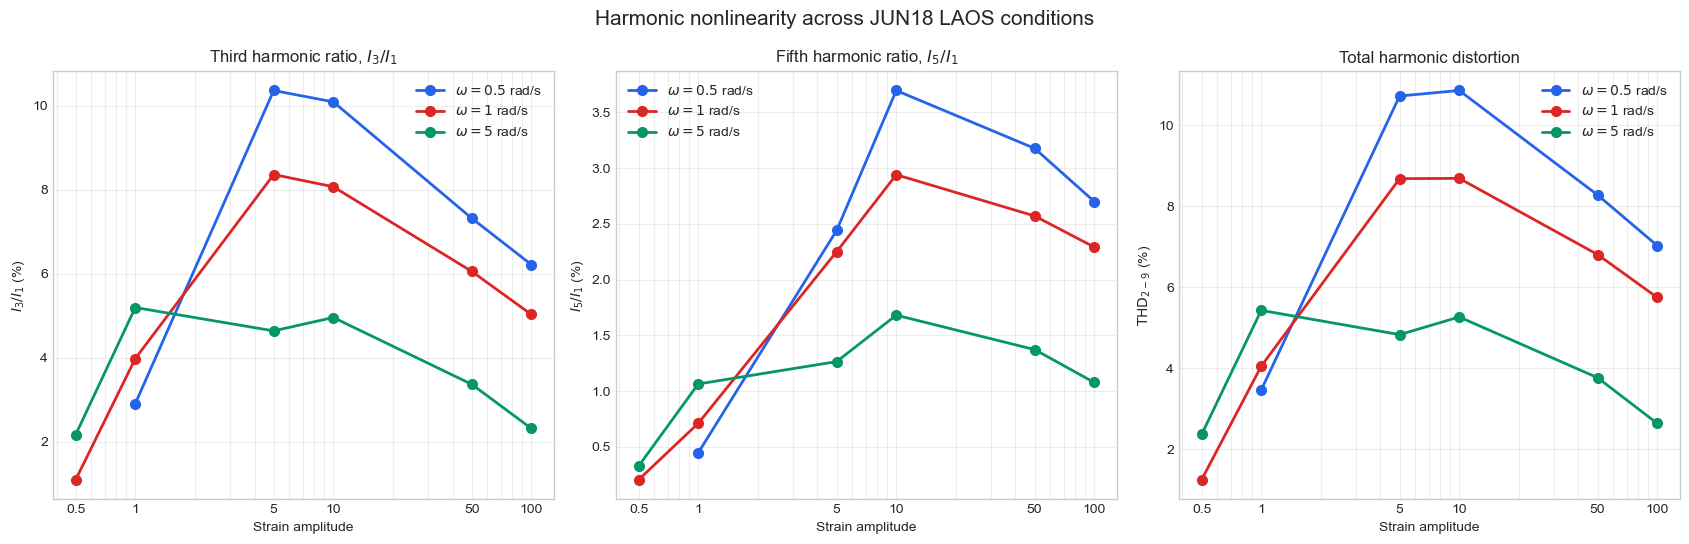

In [13]:
# Compare harmonic metrics across LAOS conditions

omega_colors = {
    0.5: "#2563EB",
    1.0: "#DC2626",
    5.0: "#059669"
}

metric_settings = [
    (
        "stress_I3_I1_pct",
        r"$I_3/I_1$ (%)",
        r"Third harmonic ratio, $I_3/I_1$"
    ),
    (
        "stress_I5_I1_pct",
        r"$I_5/I_1$ (%)",
        r"Fifth harmonic ratio, $I_5/I_1$"
    ),
    (
        "stress_THD_2_to_9_pct",
        r"$\mathrm{THD}_{2-9}$ (%)",
        "Total harmonic distortion"
    )
]


fig, axes = plt.subplots(
    1,
    3,
    figsize=(17, 5.5)
)


for axis, (
    metric_column,
    y_axis_label,
    plot_title
) in zip(axes, metric_settings):

    for omega_value, condition_group in (
        all_condition_fft.groupby(
            "omega_rad_s"
        )
    ):
        condition_group = (
            condition_group
            .sort_values(
                "strain_amplitude"
            )
        )

        axis.plot(
            condition_group[
                "strain_amplitude"
            ],
            condition_group[
                metric_column
            ],
            marker="o",
            markersize=7,
            linewidth=2,
            color=omega_colors[
                omega_value
            ],
            label=(
                rf"$\omega={omega_value:g}$ rad/s"
            )
        )

    axis.set_xscale("log")

    axis.set_xlabel(
        "Strain amplitude"
    )

    axis.set_ylabel(
        y_axis_label
    )

    axis.set_title(
        plot_title
    )

    axis.set_xticks(
        [0.5, 1, 5, 10, 50, 100]
    )

    axis.set_xticklabels(
        ["0.5", "1", "5", "10", "50", "100"]
    )

    axis.legend()

    axis.grid(
        True,
        which="both",
        alpha=0.35
    )


fig.suptitle(
    "Harmonic nonlinearity across JUN18 LAOS conditions",
    fontsize=15
)

fig.tight_layout()

plt.show()

Sampling frequency: 50.146 Hz
Samples per cycle: 63
Cycles per STFT window: 4
STFT window duration: 5.025 s
STFT frequency resolution: 0.199 Hz
Number of STFT time windows: 28


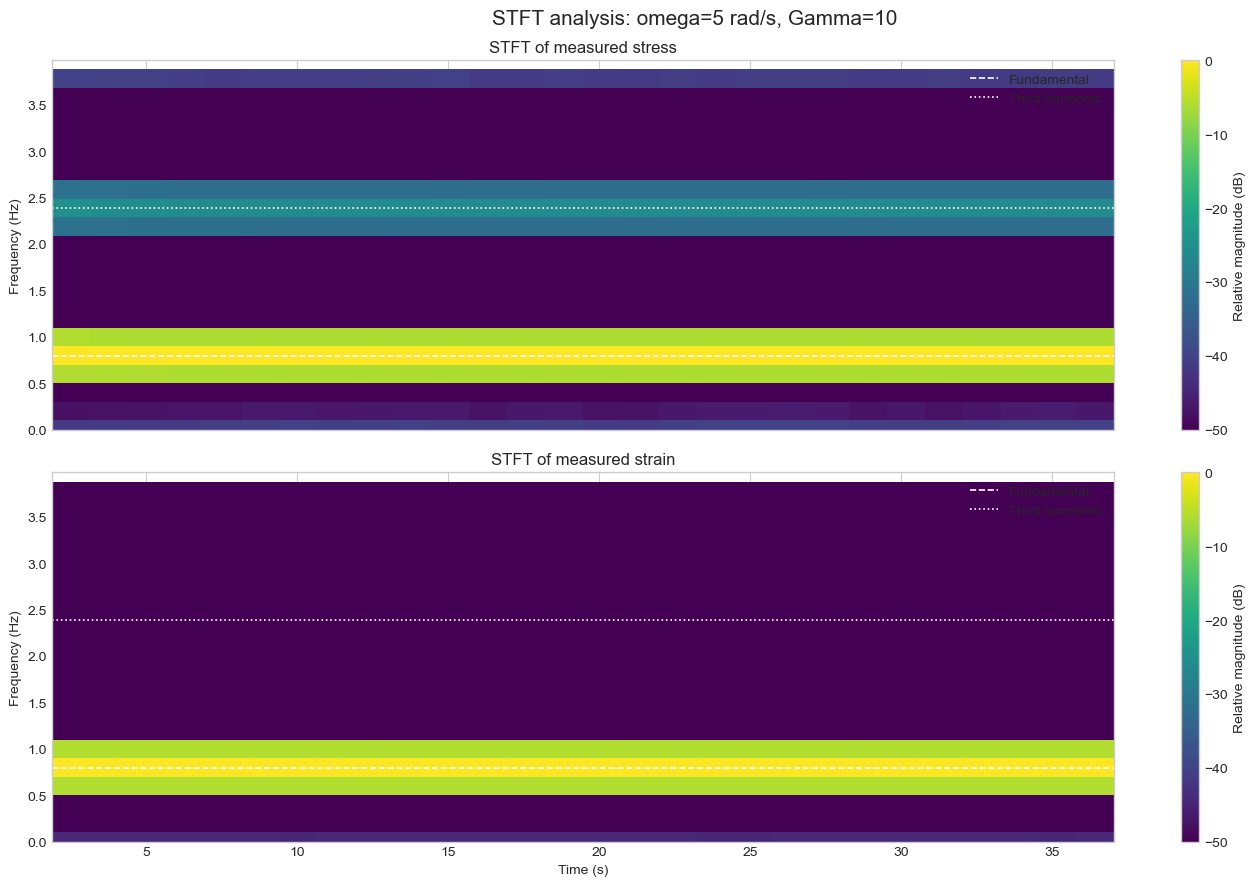

In [14]:
# Apply STFT to measured LAOS signals

from scipy.signal import stft

stft_omega = 5.0
stft_strain_amplitude = 10.0

stft_source = laos_data[
    np.isclose(
        laos_data["omega_rad_s"],
        stft_omega
    )
    &
    np.isclose(
        laos_data["strain_amplitude"],
        stft_strain_amplitude
    )
].sort_values("time_s").reset_index(drop=True)


if stft_source.empty:
    raise ValueError(
        "The selected STFT condition was not found."
    )


source_time_s = stft_source[
    "time_s"
].to_numpy()

source_stress_pa = stft_source[
    "stress_pa"
].to_numpy()

source_strain_pct = stft_source[
    "strain_pct"
].to_numpy()


stft_uniform_time_s = np.linspace(
    source_time_s[0],
    source_time_s[-1],
    num=len(source_time_s)
)

stft_uniform_stress_pa = np.interp(
    stft_uniform_time_s,
    source_time_s,
    source_stress_pa
)

stft_uniform_strain_pct = np.interp(
    stft_uniform_time_s,
    source_time_s,
    source_strain_pct
)


stft_dt_s = (
    stft_uniform_time_s[1]
    - stft_uniform_time_s[0]
)

stft_sampling_frequency_hz = (
    1 / stft_dt_s
)

stft_fundamental_hz = (
    stft_omega
    / (2 * np.pi)
)

stft_period_s = (
    2 * np.pi
    / stft_omega
)

samples_per_cycle = int(
    round(
        stft_period_s
        / stft_dt_s
    )
)

cycles_per_window = 4

window_length = (
    cycles_per_window
    * samples_per_cycle
)

overlap_length = int(
    0.75 * window_length
)


stress_frequency_hz, stft_time_s, stress_stft = stft(
    stft_uniform_stress_pa
    - stft_uniform_stress_pa.mean(),
    fs=stft_sampling_frequency_hz,
    window="hann",
    nperseg=window_length,
    noverlap=overlap_length,
    boundary=None,
    padded=False,
    scaling="spectrum"
)


strain_frequency_hz, _, strain_stft = stft(
    stft_uniform_strain_pct
    - stft_uniform_strain_pct.mean(),
    fs=stft_sampling_frequency_hz,
    window="hann",
    nperseg=window_length,
    noverlap=overlap_length,
    boundary=None,
    padded=False,
    scaling="spectrum"
)


def convert_to_relative_db(
    stft_values
):
    magnitude = np.abs(
        stft_values
    )

    maximum_magnitude = np.max(
        magnitude
    )

    relative_magnitude = (
        magnitude
        / maximum_magnitude
    )

    return 20 * np.log10(
        np.maximum(
            relative_magnitude,
            1e-12
        )
    )


stress_stft_db = convert_to_relative_db(
    stress_stft
)

strain_stft_db = convert_to_relative_db(
    strain_stft
)


frequency_resolution_hz = (
    stress_frequency_hz[1]
    - stress_frequency_hz[0]
)

print(
    f"Sampling frequency: "
    f"{stft_sampling_frequency_hz:.3f} Hz"
)

print(
    "Samples per cycle:",
    samples_per_cycle
)

print(
    "Cycles per STFT window:",
    cycles_per_window
)

print(
    f"STFT window duration: "
    f"{window_length * stft_dt_s:.3f} s"
)

print(
    f"STFT frequency resolution: "
    f"{frequency_resolution_hz:.3f} Hz"
)

print(
    "Number of STFT time windows:",
    len(stft_time_s)
)


maximum_stft_frequency_hz = (
    5 * stft_fundamental_hz
)

stress_frequency_mask = (
    stress_frequency_hz
    <= maximum_stft_frequency_hz
)

strain_frequency_mask = (
    strain_frequency_hz
    <= maximum_stft_frequency_hz
)


fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 9),
    sharex=True
)


stress_image = axes[0].pcolormesh(
    stft_time_s,
    stress_frequency_hz[
        stress_frequency_mask
    ],
    stress_stft_db[
        stress_frequency_mask,
        :
    ],
    shading="auto",
    cmap="viridis",
    vmin=-50,
    vmax=0
)

axes[0].set_ylabel(
    "Frequency (Hz)"
)

axes[0].set_title(
    "STFT of measured stress"
)

fig.colorbar(
    stress_image,
    ax=axes[0],
    label="Relative magnitude (dB)"
)


strain_image = axes[1].pcolormesh(
    stft_time_s,
    strain_frequency_hz[
        strain_frequency_mask
    ],
    strain_stft_db[
        strain_frequency_mask,
        :
    ],
    shading="auto",
    cmap="viridis",
    vmin=-50,
    vmax=0
)

axes[1].set_xlabel(
    "Time (s)"
)

axes[1].set_ylabel(
    "Frequency (Hz)"
)

axes[1].set_title(
    "STFT of measured strain"
)

fig.colorbar(
    strain_image,
    ax=axes[1],
    label="Relative magnitude (dB)"
)


for axis in axes:
    axis.axhline(
        stft_fundamental_hz,
        color="white",
        linestyle="--",
        linewidth=1.2,
        label="Fundamental"
    )

    axis.axhline(
        3 * stft_fundamental_hz,
        color="white",
        linestyle=":",
        linewidth=1.2,
        label="Third harmonic"
    )

    axis.set_ylim(
        0,
        maximum_stft_frequency_hz
    )

    axis.legend(
        loc="upper right"
    )


fig.suptitle(
    "STFT analysis: omega=5 rad/s, Gamma=10",
    fontsize=15
)

fig.tight_layout()

plt.show()

,feature,unit,mean,standard_deviation,coefficient_of_variation_pct,minimum,maximum
0,Stress fundamental amplitude,Pa,0.243742,0.001077,0.442,0.242611,0.246895
1,Stress third-harmonic amplitude,Pa,0.012266,0.000400,3.257,0.011902,0.013640
2,Stress I3/I1,%,5.031813,0.140908,2.800,4.905888,5.524586
3,Strain fundamental amplitude,%,999.560434,0.110307,0.011,999.431756,999.760303


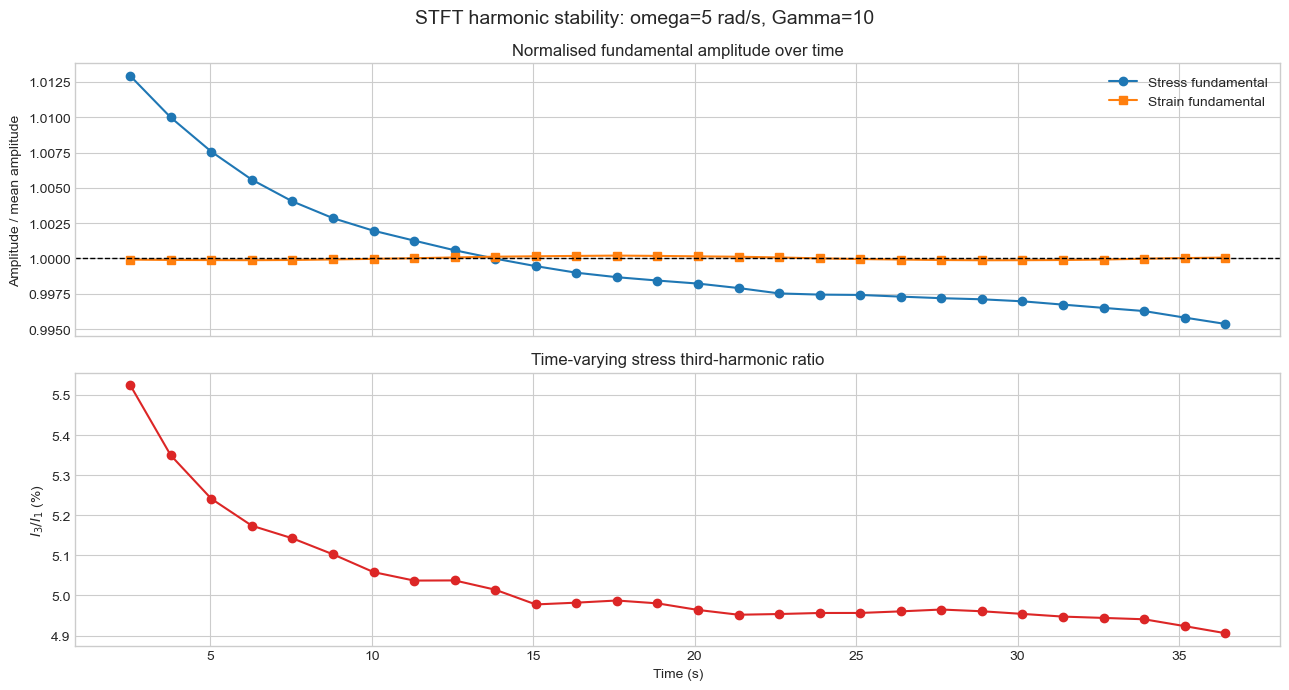

In [15]:
# Quantify STFT harmonic stability

fundamental_frequency_index = np.argmin(
    np.abs(
        stress_frequency_hz
        - stft_fundamental_hz
    )
)

third_harmonic_frequency_index = np.argmin(
    np.abs(
        stress_frequency_hz
        - 3 * stft_fundamental_hz
    )
)


stress_fundamental_over_time = (
    2
    * np.abs(
        stress_stft[
            fundamental_frequency_index,
            :
        ]
    )
)

stress_third_harmonic_over_time = (
    2
    * np.abs(
        stress_stft[
            third_harmonic_frequency_index,
            :
        ]
    )
)

strain_fundamental_over_time = (
    2
    * np.abs(
        strain_stft[
            fundamental_frequency_index,
            :
        ]
    )
)


stress_I3_I1_over_time = (
    stress_third_harmonic_over_time
    / stress_fundamental_over_time
    * 100
)


def summarize_time_variation(
    feature_name,
    values,
    unit
):
    values = np.asarray(
        values,
        dtype=float
    )

    return {
        "feature": feature_name,
        "unit": unit,
        "mean": values.mean(),
        "standard_deviation": values.std(
            ddof=1
        ),
        "coefficient_of_variation_pct": (
            values.std(ddof=1)
            / values.mean()
            * 100
        ),
        "minimum": values.min(),
        "maximum": values.max()
    }


stft_stability_summary = pd.DataFrame(
    [
        summarize_time_variation(
            "Stress fundamental amplitude",
            stress_fundamental_over_time,
            "Pa"
        ),
        summarize_time_variation(
            "Stress third-harmonic amplitude",
            stress_third_harmonic_over_time,
            "Pa"
        ),
        summarize_time_variation(
            "Stress I3/I1",
            stress_I3_I1_over_time,
            "%"
        ),
        summarize_time_variation(
            "Strain fundamental amplitude",
            strain_fundamental_over_time,
            "%"
        )
    ]
)


display(
    stft_stability_summary.round(
        {
            "mean": 6,
            "standard_deviation": 6,
            "coefficient_of_variation_pct": 3,
            "minimum": 6,
            "maximum": 6
        }
    )
)


fig, axes = plt.subplots(
    2,
    1,
    figsize=(13, 7),
    sharex=True
)


axes[0].plot(
    stft_time_s,
    stress_fundamental_over_time
    / stress_fundamental_over_time.mean(),
    marker="o",
    linewidth=1.5,
    label="Stress fundamental"
)

axes[0].plot(
    stft_time_s,
    strain_fundamental_over_time
    / strain_fundamental_over_time.mean(),
    marker="s",
    linewidth=1.5,
    label="Strain fundamental"
)

axes[0].axhline(
    1.0,
    color="black",
    linestyle="--",
    linewidth=1
)

axes[0].set_ylabel(
    "Amplitude / mean amplitude"
)

axes[0].set_title(
    "Normalised fundamental amplitude over time"
)

axes[0].legend()


axes[1].plot(
    stft_time_s,
    stress_I3_I1_over_time,
    color="#DC2626",
    marker="o",
    linewidth=1.5
)

axes[1].set_xlabel(
    "Time (s)"
)

axes[1].set_ylabel(
    r"$I_3/I_1$ (%)"
)

axes[1].set_title(
    "Time-varying stress third-harmonic ratio"
)


fig.suptitle(
    "STFT harmonic stability: omega=5 rad/s, Gamma=10",
    fontsize=14
)

fig.tight_layout()

plt.show()

Wavelet: cmor1.5-1.0
Number of CWT frequencies: 128
CWT frequency range: 0.200 to 3.979 Hz


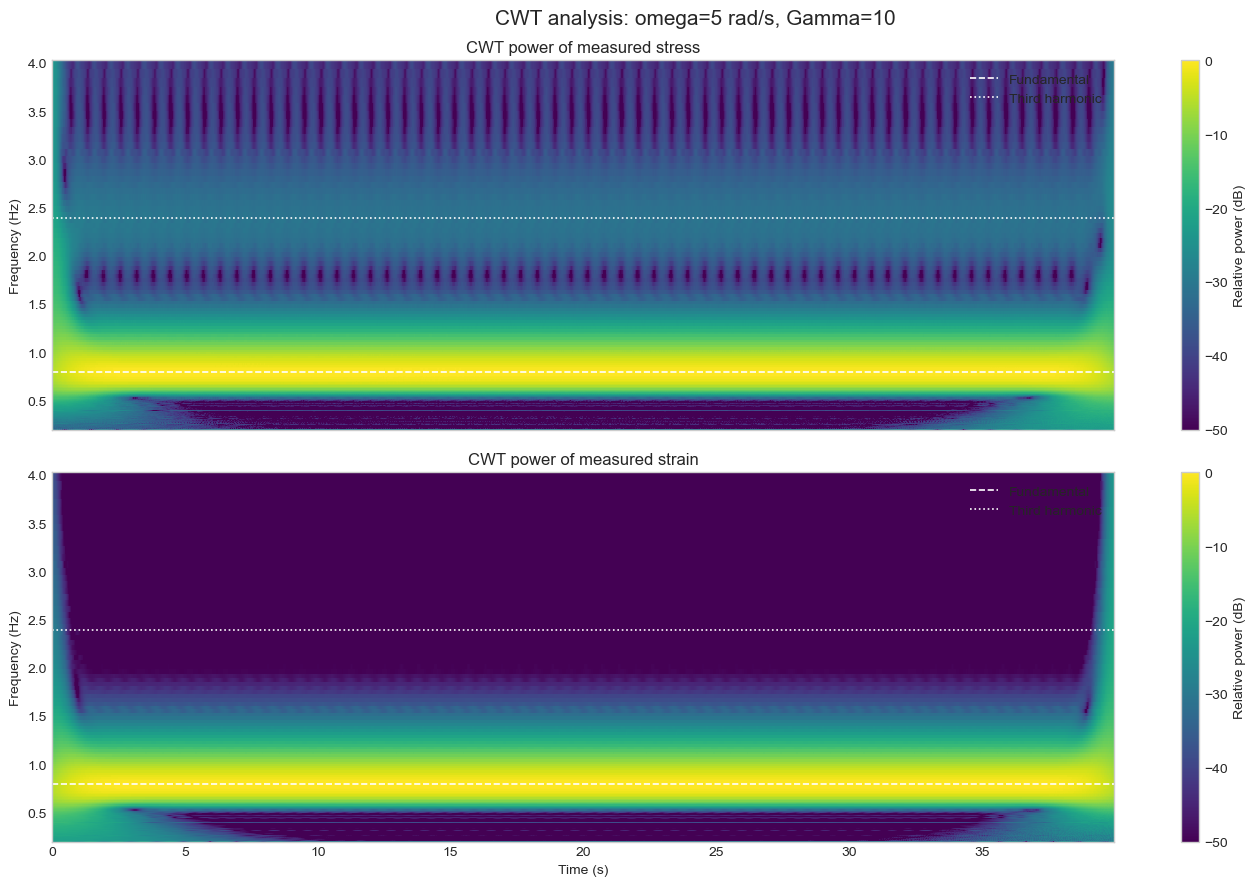

In [16]:
# Apply Continuous Wavelet Transform

import pywt

cwt_time_s = (
    stft_uniform_time_s
    - stft_uniform_time_s[0]
)

cwt_stress_signal = (
    stft_uniform_stress_pa
    - stft_uniform_stress_pa.mean()
)

cwt_strain_signal = (
    stft_uniform_strain_pct
    - stft_uniform_strain_pct.mean()
)


minimum_cwt_frequency_hz = 0.2

maximum_cwt_frequency_hz = (
    5 * stft_fundamental_hz
)

target_cwt_frequencies_hz = np.geomspace(
    minimum_cwt_frequency_hz,
    maximum_cwt_frequency_hz,
    num=128
)


wavelet_name = "cmor1.5-1.0"

wavelet_central_frequency = (
    pywt.central_frequency(
        wavelet_name
    )
)

cwt_scales = (
    wavelet_central_frequency
    / (
        target_cwt_frequencies_hz
        * stft_dt_s
    )
)


stress_cwt_coefficients, stress_cwt_frequencies_hz = (
    pywt.cwt(
        cwt_stress_signal,
        cwt_scales,
        wavelet_name,
        sampling_period=stft_dt_s
    )
)

strain_cwt_coefficients, strain_cwt_frequencies_hz = (
    pywt.cwt(
        cwt_strain_signal,
        cwt_scales,
        wavelet_name,
        sampling_period=stft_dt_s
    )
)


stress_cwt_power = (
    np.abs(
        stress_cwt_coefficients
    ) ** 2
)

strain_cwt_power = (
    np.abs(
        strain_cwt_coefficients
    ) ** 2
)


stress_cwt_power_db = (
    10
    * np.log10(
        np.maximum(
            stress_cwt_power
            / stress_cwt_power.max(),
            1e-12
        )
    )
)

strain_cwt_power_db = (
    10
    * np.log10(
        np.maximum(
            strain_cwt_power
            / strain_cwt_power.max(),
            1e-12
        )
    )
)


print(
    "Wavelet:",
    wavelet_name
)

print(
    "Number of CWT frequencies:",
    len(target_cwt_frequencies_hz)
)

print(
    f"CWT frequency range: "
    f"{target_cwt_frequencies_hz.min():.3f} "
    f"to "
    f"{target_cwt_frequencies_hz.max():.3f} Hz"
)


fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 9),
    sharex=True
)


stress_cwt_image = axes[0].pcolormesh(
    cwt_time_s,
    stress_cwt_frequencies_hz,
    stress_cwt_power_db,
    shading="auto",
    cmap="viridis",
    vmin=-50,
    vmax=0
)

axes[0].axhline(
    stft_fundamental_hz,
    color="white",
    linestyle="--",
    linewidth=1.2,
    label="Fundamental"
)

axes[0].axhline(
    3 * stft_fundamental_hz,
    color="white",
    linestyle=":",
    linewidth=1.2,
    label="Third harmonic"
)

axes[0].set_ylabel(
    "Frequency (Hz)"
)

axes[0].set_title(
    "CWT power of measured stress"
)

axes[0].legend(
    loc="upper right"
)

fig.colorbar(
    stress_cwt_image,
    ax=axes[0],
    label="Relative power (dB)"
)


strain_cwt_image = axes[1].pcolormesh(
    cwt_time_s,
    strain_cwt_frequencies_hz,
    strain_cwt_power_db,
    shading="auto",
    cmap="viridis",
    vmin=-50,
    vmax=0
)

axes[1].axhline(
    stft_fundamental_hz,
    color="white",
    linestyle="--",
    linewidth=1.2,
    label="Fundamental"
)

axes[1].axhline(
    3 * stft_fundamental_hz,
    color="white",
    linestyle=":",
    linewidth=1.2,
    label="Third harmonic"
)

axes[1].set_xlabel(
    "Time (s)"
)

axes[1].set_ylabel(
    "Frequency (Hz)"
)

axes[1].set_title(
    "CWT power of measured strain"
)

axes[1].legend(
    loc="upper right"
)

fig.colorbar(
    strain_cwt_image,
    ax=axes[1],
    label="Relative power (dB)"
)


fig.suptitle(
    "CWT analysis: omega=5 rad/s, Gamma=10",
    fontsize=15
)

fig.tight_layout()

plt.show()

,feature,coefficient_of_variation_pct,first_to_last_change_pct
0,Stress fundamental band power,0.786,-1.815
1,Stress third-harmonic band power,5.564,-11.040
2,Strain fundamental band power,0.052,-0.022


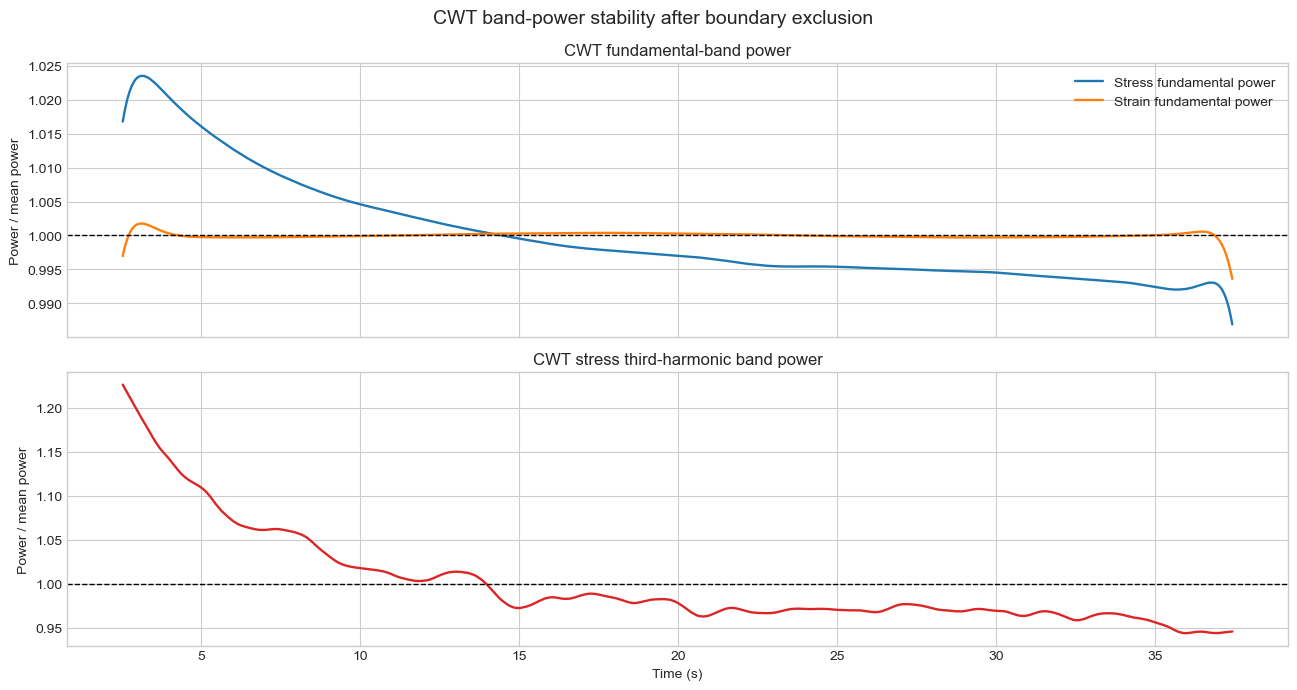

In [17]:
# Quantify CWT band-power stability

def calculate_cwt_band_power(
    cwt_power,
    cwt_frequencies_hz,
    centre_frequency_hz,
    relative_bandwidth=0.20
):
    lower_frequency = (
        centre_frequency_hz
        * (1 - relative_bandwidth)
    )

    upper_frequency = (
        centre_frequency_hz
        * (1 + relative_bandwidth)
    )

    frequency_mask = (
        (cwt_frequencies_hz >= lower_frequency)
        &
        (cwt_frequencies_hz <= upper_frequency)
    )

    return cwt_power[
        frequency_mask,
        :
    ].mean(axis=0)


stress_fundamental_cwt_power = (
    calculate_cwt_band_power(
        stress_cwt_power,
        stress_cwt_frequencies_hz,
        stft_fundamental_hz
    )
)

stress_third_cwt_power = (
    calculate_cwt_band_power(
        stress_cwt_power,
        stress_cwt_frequencies_hz,
        3 * stft_fundamental_hz
    )
)

strain_fundamental_cwt_power = (
    calculate_cwt_band_power(
        strain_cwt_power,
        strain_cwt_frequencies_hz,
        stft_fundamental_hz
    )
)


cycle_average_points = (
    samples_per_cycle
)

stress_fundamental_cwt_smooth = (
    pd.Series(
        stress_fundamental_cwt_power
    )
    .rolling(
        window=cycle_average_points,
        center=True,
        min_periods=cycle_average_points // 2
    )
    .mean()
    .to_numpy()
)

stress_third_cwt_smooth = (
    pd.Series(
        stress_third_cwt_power
    )
    .rolling(
        window=cycle_average_points,
        center=True,
        min_periods=cycle_average_points // 2
    )
    .mean()
    .to_numpy()
)

strain_fundamental_cwt_smooth = (
    pd.Series(
        strain_fundamental_cwt_power
    )
    .rolling(
        window=cycle_average_points,
        center=True,
        min_periods=cycle_average_points // 2
    )
    .mean()
    .to_numpy()
)


boundary_exclusion_s = (
    2 * stft_period_s
)

interior_time_mask = (
    (cwt_time_s >= boundary_exclusion_s)
    &
    (
        cwt_time_s
        <= cwt_time_s[-1]
        - boundary_exclusion_s
    )
)

interior_time_s = cwt_time_s[
    interior_time_mask
]


def summarize_cwt_variation(
    feature_name,
    smoothed_power
):
    interior_power = smoothed_power[
        interior_time_mask
    ]

    quarter_length = (
        len(interior_power) // 4
    )

    first_quarter_mean = np.mean(
        interior_power[
            :quarter_length
        ]
    )

    last_quarter_mean = np.mean(
        interior_power[
            -quarter_length:
        ]
    )

    return {
        "feature": feature_name,
        "coefficient_of_variation_pct": (
            np.std(
                interior_power,
                ddof=1
            )
            / np.mean(interior_power)
            * 100
        ),
        "first_to_last_change_pct": (
            last_quarter_mean
            / first_quarter_mean
            - 1
        ) * 100
    }


cwt_stability_summary = pd.DataFrame(
    [
        summarize_cwt_variation(
            "Stress fundamental band power",
            stress_fundamental_cwt_smooth
        ),
        summarize_cwt_variation(
            "Stress third-harmonic band power",
            stress_third_cwt_smooth
        ),
        summarize_cwt_variation(
            "Strain fundamental band power",
            strain_fundamental_cwt_smooth
        )
    ]
)


display(
    cwt_stability_summary.round(3)
)


normalised_stress_fundamental = (
    stress_fundamental_cwt_smooth[
        interior_time_mask
    ]
    / np.mean(
        stress_fundamental_cwt_smooth[
            interior_time_mask
        ]
    )
)

normalised_stress_third = (
    stress_third_cwt_smooth[
        interior_time_mask
    ]
    / np.mean(
        stress_third_cwt_smooth[
            interior_time_mask
        ]
    )
)

normalised_strain_fundamental = (
    strain_fundamental_cwt_smooth[
        interior_time_mask
    ]
    / np.mean(
        strain_fundamental_cwt_smooth[
            interior_time_mask
        ]
    )
)


fig, axes = plt.subplots(
    2,
    1,
    figsize=(13, 7),
    sharex=True
)


axes[0].plot(
    interior_time_s,
    normalised_stress_fundamental,
    label="Stress fundamental power",
    linewidth=1.7
)

axes[0].plot(
    interior_time_s,
    normalised_strain_fundamental,
    label="Strain fundamental power",
    linewidth=1.7
)

axes[0].axhline(
    1.0,
    color="black",
    linestyle="--",
    linewidth=1
)

axes[0].set_ylabel(
    "Power / mean power"
)

axes[0].set_title(
    "CWT fundamental-band power"
)

axes[0].legend()


axes[1].plot(
    interior_time_s,
    normalised_stress_third,
    color="#DC2626",
    linewidth=1.7
)

axes[1].axhline(
    1.0,
    color="black",
    linestyle="--",
    linewidth=1
)

axes[1].set_xlabel(
    "Time (s)"
)

axes[1].set_ylabel(
    "Power / mean power"
)

axes[1].set_title(
    "CWT stress third-harmonic band power"
)


fig.suptitle(
    "CWT band-power stability after boundary exclusion",
    fontsize=14
)

fig.tight_layout()

plt.show()

,excluded_periods_at_each_end,interior_start_time_s,interior_end_time_s,stress_fundamental_cv_pct,stress_fundamental_change_pct,stress_third_cv_pct,stress_third_change_pct,strain_fundamental_cv_pct,strain_fundamental_change_pct
0,2,2.533,37.431,0.786,-1.815,5.564,-11.040,0.052,-0.022
1,3,3.789,36.174,0.668,-1.558,4.283,-8.841,0.023,-0.000
2,4,5.045,34.918,0.553,-1.314,3.396,-7.126,0.023,-0.006
3,5,6.302,33.662,0.462,-1.113,2.836,-6.003,0.023,-0.015
4,6,7.558,32.405,0.389,-0.948,2.377,-5.102,0.023,-0.022


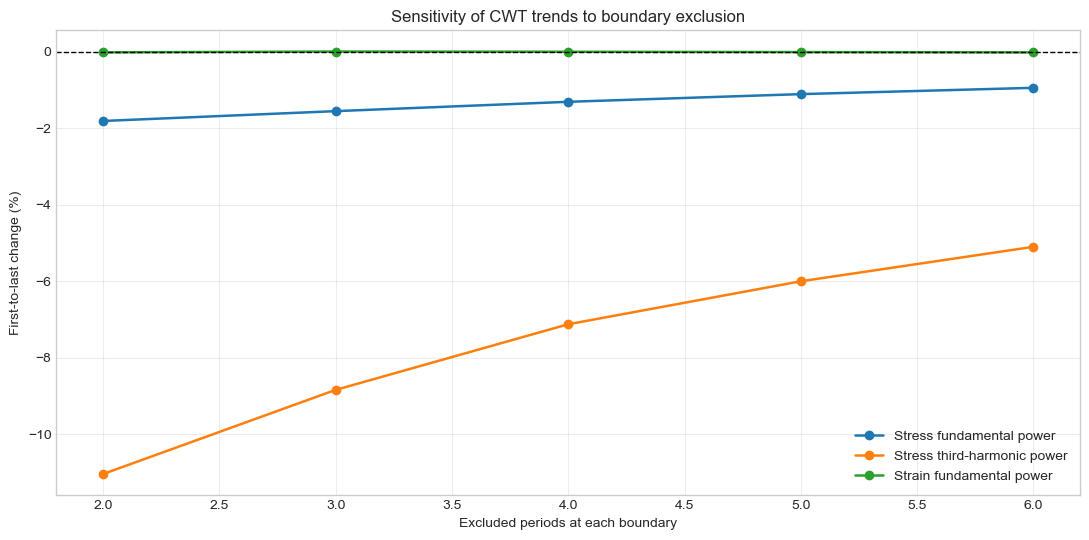

In [18]:
# Test CWT boundary sensitivity

boundary_sensitivity_rows = []


def calculate_interior_change(
    smoothed_power,
    valid_time_mask
):
    interior_power = smoothed_power[
        valid_time_mask
    ]

    quarter_length = (
        len(interior_power) // 4
    )

    first_quarter_mean = np.mean(
        interior_power[
            :quarter_length
        ]
    )

    last_quarter_mean = np.mean(
        interior_power[
            -quarter_length:
        ]
    )

    coefficient_of_variation = (
        np.std(
            interior_power,
            ddof=1
        )
        / np.mean(interior_power)
        * 100
    )

    first_to_last_change = (
        last_quarter_mean
        / first_quarter_mean
        - 1
    ) * 100

    return (
        coefficient_of_variation,
        first_to_last_change
    )


for excluded_periods in [
    2,
    3,
    4,
    5,
    6
]:
    exclusion_duration_s = (
        excluded_periods
        * stft_period_s
    )

    valid_time_mask = (
        (
            cwt_time_s
            >= exclusion_duration_s
        )
        &
        (
            cwt_time_s
            <= cwt_time_s[-1]
            - exclusion_duration_s
        )
    )

    (
        stress_fundamental_cv,
        stress_fundamental_change
    ) = calculate_interior_change(
        stress_fundamental_cwt_smooth,
        valid_time_mask
    )

    (
        stress_third_cv,
        stress_third_change
    ) = calculate_interior_change(
        stress_third_cwt_smooth,
        valid_time_mask
    )

    (
        strain_fundamental_cv,
        strain_fundamental_change
    ) = calculate_interior_change(
        strain_fundamental_cwt_smooth,
        valid_time_mask
    )

    valid_times = cwt_time_s[
        valid_time_mask
    ]

    boundary_sensitivity_rows.append(
        {
            "excluded_periods_at_each_end": (
                excluded_periods
            ),
            "interior_start_time_s": (
                valid_times[0]
            ),
            "interior_end_time_s": (
                valid_times[-1]
            ),
            "stress_fundamental_cv_pct": (
                stress_fundamental_cv
            ),
            "stress_fundamental_change_pct": (
                stress_fundamental_change
            ),
            "stress_third_cv_pct": (
                stress_third_cv
            ),
            "stress_third_change_pct": (
                stress_third_change
            ),
            "strain_fundamental_cv_pct": (
                strain_fundamental_cv
            ),
            "strain_fundamental_change_pct": (
                strain_fundamental_change
            )
        }
    )


boundary_sensitivity = pd.DataFrame(
    boundary_sensitivity_rows
)


display(
    boundary_sensitivity.round(3)
)


fig, axis = plt.subplots(
    figsize=(11, 5.5)
)


axis.plot(
    boundary_sensitivity[
        "excluded_periods_at_each_end"
    ],
    boundary_sensitivity[
        "stress_fundamental_change_pct"
    ],
    marker="o",
    linewidth=1.8,
    label="Stress fundamental power"
)

axis.plot(
    boundary_sensitivity[
        "excluded_periods_at_each_end"
    ],
    boundary_sensitivity[
        "stress_third_change_pct"
    ],
    marker="o",
    linewidth=1.8,
    label="Stress third-harmonic power"
)

axis.plot(
    boundary_sensitivity[
        "excluded_periods_at_each_end"
    ],
    boundary_sensitivity[
        "strain_fundamental_change_pct"
    ],
    marker="o",
    linewidth=1.8,
    label="Strain fundamental power"
)


axis.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

axis.set_xlabel(
    "Excluded periods at each boundary"
)

axis.set_ylabel(
    "First-to-last change (%)"
)

axis.set_title(
    "Sensitivity of CWT trends to boundary exclusion"
)

axis.legend()

axis.grid(
    True,
    alpha=0.35
)

fig.tight_layout()

plt.show()

Wavelet: db4
Decomposition level: 7
Number of complete cycles used: 23
Number of signal points: 1450


,band,approximate_frequency_range_hz,expected_component,stress_energy_pct,strain_energy_pct
0,A7,0.000–0.196,,0.064091,0.091278
1,D7,0.196–0.392,,0.101983,0.616053
2,D6,0.392–0.784,,63.860392,35.002647
3,D5,0.784–1.567,Fundamental,34.673014,63.040293
4,D4,1.567–3.134,Third harmonic,1.200663,1.231099
5,D3,3.134–6.268,Fifth harmonic,0.076480,0.018209
6,D2,6.268–12.536,,0.011936,0.000412
7,D1,12.536–25.073,,0.011439,0.000010


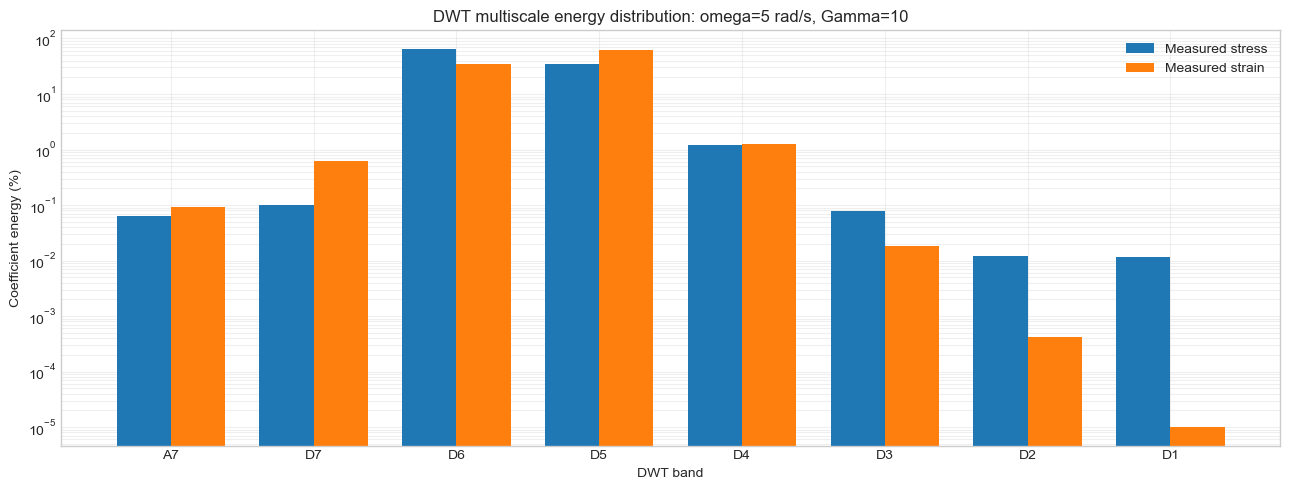

In [19]:
# DWT multiscale energy decomposition

import pywt
from scipy.signal import find_peaks

DWT_WAVELET = "db4"
DWT_EXCLUDED_PERIODS_AT_EACH_END = 4

# Detect strain peaks in the uniformly sampled signal
dwt_peak_indices, _ = find_peaks(
    stft_uniform_strain_pct,
    distance=max(1, int(0.8 * samples_per_cycle)),
    prominence=0.5 * np.std(stft_uniform_strain_pct),
)

minimum_required_peaks = (
    2 * DWT_EXCLUDED_PERIODS_AT_EACH_END + 2
)

if len(dwt_peak_indices) < minimum_required_peaks:
    raise ValueError(
        "Not enough complete cycles for the requested boundary exclusion."
    )

# Select a phase-matched interior interval
dwt_start_peak_position = DWT_EXCLUDED_PERIODS_AT_EACH_END

dwt_end_peak_position = (
    len(dwt_peak_indices)
    - DWT_EXCLUDED_PERIODS_AT_EACH_END
    - 1
)

dwt_start_index = dwt_peak_indices[dwt_start_peak_position]
dwt_end_index = dwt_peak_indices[dwt_end_peak_position]

dwt_time_s = (
    stft_uniform_time_s[dwt_start_index:dwt_end_index]
    - stft_uniform_time_s[dwt_start_index]
)

dwt_stress_pa = stft_uniform_stress_pa[
    dwt_start_index:dwt_end_index
].copy()

dwt_strain_pct = stft_uniform_strain_pct[
    dwt_start_index:dwt_end_index
].copy()

# Remove the mean before decomposition
dwt_stress_pa -= np.mean(dwt_stress_pa)
dwt_strain_pct -= np.mean(dwt_strain_pct)

# Determine the maximum valid decomposition level
dwt_wavelet = pywt.Wavelet(DWT_WAVELET)

maximum_allowed_level = pywt.dwt_max_level(
    len(dwt_stress_pa),
    dwt_wavelet.dec_len,
)

dwt_level = min(8, maximum_allowed_level)

# Perform DWT
stress_coefficients = pywt.wavedec(
    dwt_stress_pa,
    wavelet=dwt_wavelet,
    mode="periodization",
    level=dwt_level,
)

strain_coefficients = pywt.wavedec(
    dwt_strain_pct,
    wavelet=dwt_wavelet,
    mode="periodization",
    level=dwt_level,
)

band_labels = (
    [f"A{dwt_level}"]
    + [f"D{level}" for level in range(dwt_level, 0, -1)]
)

# Calculate coefficient energy
stress_energy = np.array(
    [
        np.sum(coefficient**2)
        for coefficient in stress_coefficients
    ]
)

strain_energy = np.array(
    [
        np.sum(coefficient**2)
        for coefficient in strain_coefficients
    ]
)

stress_energy_pct = (
    100 * stress_energy / np.sum(stress_energy)
)

strain_energy_pct = (
    100 * strain_energy / np.sum(strain_energy)
)

expected_components = {
    "Fundamental": stft_fundamental_hz,
    "Third harmonic": 3 * stft_fundamental_hz,
    "Fifth harmonic": 5 * stft_fundamental_hz,
}

# Construct the energy table
dwt_rows = []

for band, stress_pct, strain_pct in zip(
    band_labels,
    stress_energy_pct,
    strain_energy_pct,
):
    if band.startswith("A"):
        lower_frequency_hz = 0.0
        upper_frequency_hz = (
            stft_sampling_frequency_hz
            / (2 ** (dwt_level + 1))
        )
    else:
        detail_level = int(band[1:])

        lower_frequency_hz = (
            stft_sampling_frequency_hz
            / (2 ** (detail_level + 1))
        )

        upper_frequency_hz = (
            stft_sampling_frequency_hz
            / (2 ** detail_level)
        )

    components_in_band = [
        name
        for name, frequency_hz in expected_components.items()
        if lower_frequency_hz
        <= frequency_hz
        <= upper_frequency_hz
    ]

    dwt_rows.append(
        {
            "band": band,
            "approximate_frequency_range_hz": (
                f"{lower_frequency_hz:.3f}–"
                f"{upper_frequency_hz:.3f}"
            ),
            "expected_component": (
                ", ".join(components_in_band)
                if components_in_band
                else ""
            ),
            "stress_energy_pct": stress_pct,
            "strain_energy_pct": strain_pct,
        }
    )

dwt_energy_table = pd.DataFrame(dwt_rows)

number_of_cycles_used = (
    dwt_end_peak_position - dwt_start_peak_position
)

print(f"Wavelet: {DWT_WAVELET}")
print(f"Decomposition level: {dwt_level}")
print(
    f"Number of complete cycles used: "
    f"{number_of_cycles_used}"
)
print(f"Number of signal points: {len(dwt_stress_pa)}")

# Display the table without using pandas Styler
display(
    dwt_energy_table.round(
        {
            "stress_energy_pct": 6,
            "strain_energy_pct": 6,
        }
    )
)

# Plot energy distribution across DWT bands
x_positions = np.arange(len(dwt_energy_table))
bar_width = 0.38

fig, ax = plt.subplots(figsize=(13, 5))

ax.bar(
    x_positions - bar_width / 2,
    dwt_energy_table["stress_energy_pct"],
    width=bar_width,
    label="Measured stress",
)

ax.bar(
    x_positions + bar_width / 2,
    dwt_energy_table["strain_energy_pct"],
    width=bar_width,
    label="Measured strain",
)

ax.set_yscale("log")
ax.set_xticks(x_positions)
ax.set_xticklabels(dwt_energy_table["band"])
ax.set_xlabel("DWT band")
ax.set_ylabel("Coefficient energy (%)")
ax.set_title(
    "DWT multiscale energy distribution: "
    "omega=5 rad/s, Gamma=10"
)
ax.legend()
ax.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()

,component,bands,stress_energy_pct,strain_energy_pct
0,Low-frequency component,"A7, D7",0.166074,0.707330
1,Fundamental-scale component,"D6, D5",98.533407,98.042940
2,Third-harmonic-scale component,D4,1.200663,1.231099
3,High-frequency detail,"D3, D2, D1",0.099856,0.018631


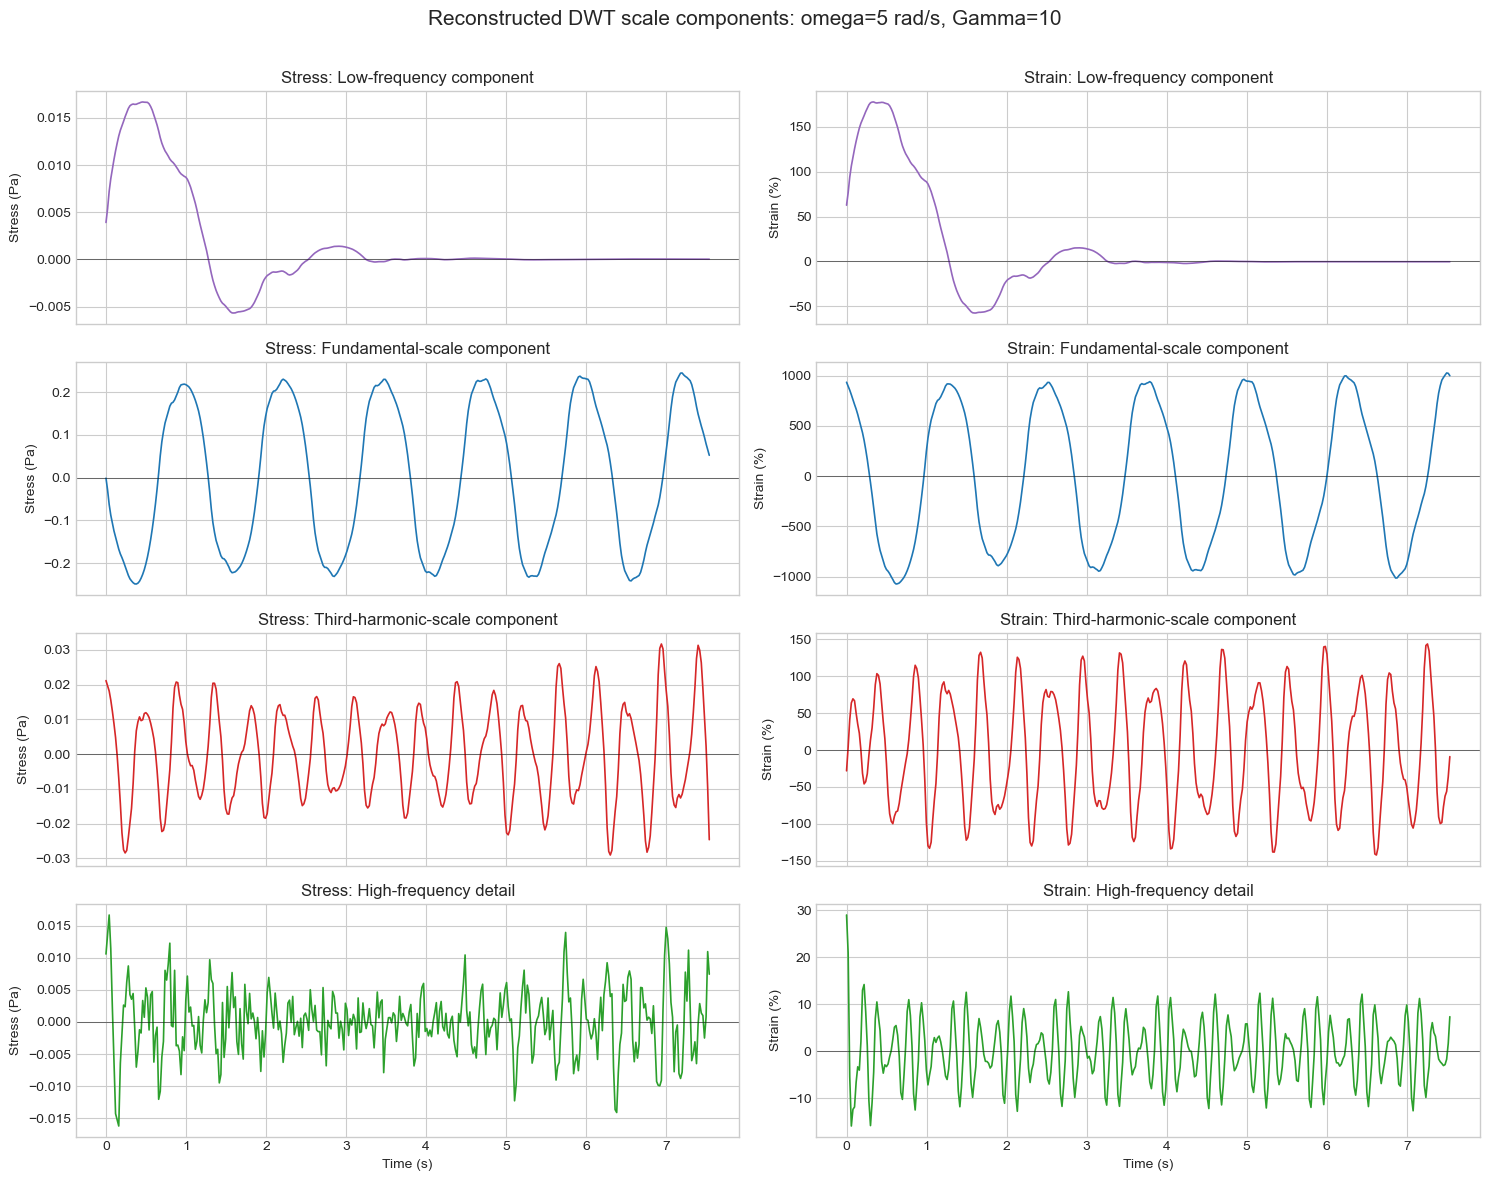

In [20]:
# Reconstruct grouped DWT scale components

dwt_group_definitions = {
    "Low-frequency component": ["A7", "D7"],
    "Fundamental-scale component": ["D6", "D5"],
    "Third-harmonic-scale component": ["D4"],
    "High-frequency detail": ["D3", "D2", "D1"],
}


def reconstruct_dwt_group(
    coefficients,
    selected_bands,
):
    selected_coefficients = [
        coefficient.copy()
        if band in selected_bands
        else np.zeros_like(coefficient)
        for band, coefficient in zip(
            band_labels,
            coefficients,
        )
    ]

    reconstructed_signal = pywt.waverec(
        selected_coefficients,
        wavelet=dwt_wavelet,
        mode="periodization",
    )

    return reconstructed_signal[:len(dwt_time_s)]


# Reconstruct stress and strain components
stress_dwt_components = {}
strain_dwt_components = {}

for group_name, selected_bands in dwt_group_definitions.items():
    stress_dwt_components[group_name] = reconstruct_dwt_group(
        stress_coefficients,
        selected_bands,
    )

    strain_dwt_components[group_name] = reconstruct_dwt_group(
        strain_coefficients,
        selected_bands,
    )


# Summarise grouped coefficient energies
dwt_group_rows = []

for group_name, selected_bands in dwt_group_definitions.items():
    selected_rows = dwt_energy_table[
        dwt_energy_table["band"].isin(selected_bands)
    ]

    dwt_group_rows.append(
        {
            "component": group_name,
            "bands": ", ".join(selected_bands),
            "stress_energy_pct": selected_rows[
                "stress_energy_pct"
            ].sum(),
            "strain_energy_pct": selected_rows[
                "strain_energy_pct"
            ].sum(),
        }
    )

dwt_group_energy_table = pd.DataFrame(dwt_group_rows)

display(
    dwt_group_energy_table.round(
        {
            "stress_energy_pct": 6,
            "strain_energy_pct": 6,
        }
    )
)


# Plot the first six cycles of each reconstructed component
number_of_cycles_to_plot = 6

dwt_plot_end_time_s = min(
    dwt_time_s[-1],
    number_of_cycles_to_plot / stft_fundamental_hz,
)

dwt_plot_mask = dwt_time_s <= dwt_plot_end_time_s

component_colours = {
    "Low-frequency component": "tab:purple",
    "Fundamental-scale component": "tab:blue",
    "Third-harmonic-scale component": "tab:red",
    "High-frequency detail": "tab:green",
}

fig, axes = plt.subplots(
    nrows=4,
    ncols=2,
    figsize=(15, 12),
    sharex=True,
)

for row_index, group_name in enumerate(
    dwt_group_definitions
):
    colour = component_colours[group_name]

    axes[row_index, 0].plot(
        dwt_time_s[dwt_plot_mask],
        stress_dwt_components[group_name][dwt_plot_mask],
        color=colour,
        linewidth=1.2,
    )

    axes[row_index, 1].plot(
        dwt_time_s[dwt_plot_mask],
        strain_dwt_components[group_name][dwt_plot_mask],
        color=colour,
        linewidth=1.2,
    )

    axes[row_index, 0].axhline(
        0,
        color="black",
        linewidth=0.7,
        alpha=0.5,
    )

    axes[row_index, 1].axhline(
        0,
        color="black",
        linewidth=0.7,
        alpha=0.5,
    )

    axes[row_index, 0].set_title(
        f"Stress: {group_name}"
    )

    axes[row_index, 1].set_title(
        f"Strain: {group_name}"
    )

    axes[row_index, 0].set_ylabel("Stress (Pa)")
    axes[row_index, 1].set_ylabel("Strain (%)")

axes[-1, 0].set_xlabel("Time (s)")
axes[-1, 1].set_xlabel("Time (s)")

fig.suptitle(
    "Reconstructed DWT scale components: "
    "omega=5 rad/s, Gamma=10",
    fontsize=15,
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

Number of analysed cycles: 23


,feature,unit,mean,coefficient_of_variation_pct,fitted_first_to_last_change_pct
0,Stress fundamental amplitude,Pa,0.243539,0.265,-0.785
1,Stress third-harmonic ratio,%,4.999384,1.461,-3.785
2,Stress fifth-harmonic ratio,%,1.770741,4.068,-3.709
3,Strain fundamental amplitude,%,999.570540,0.012,-0.009


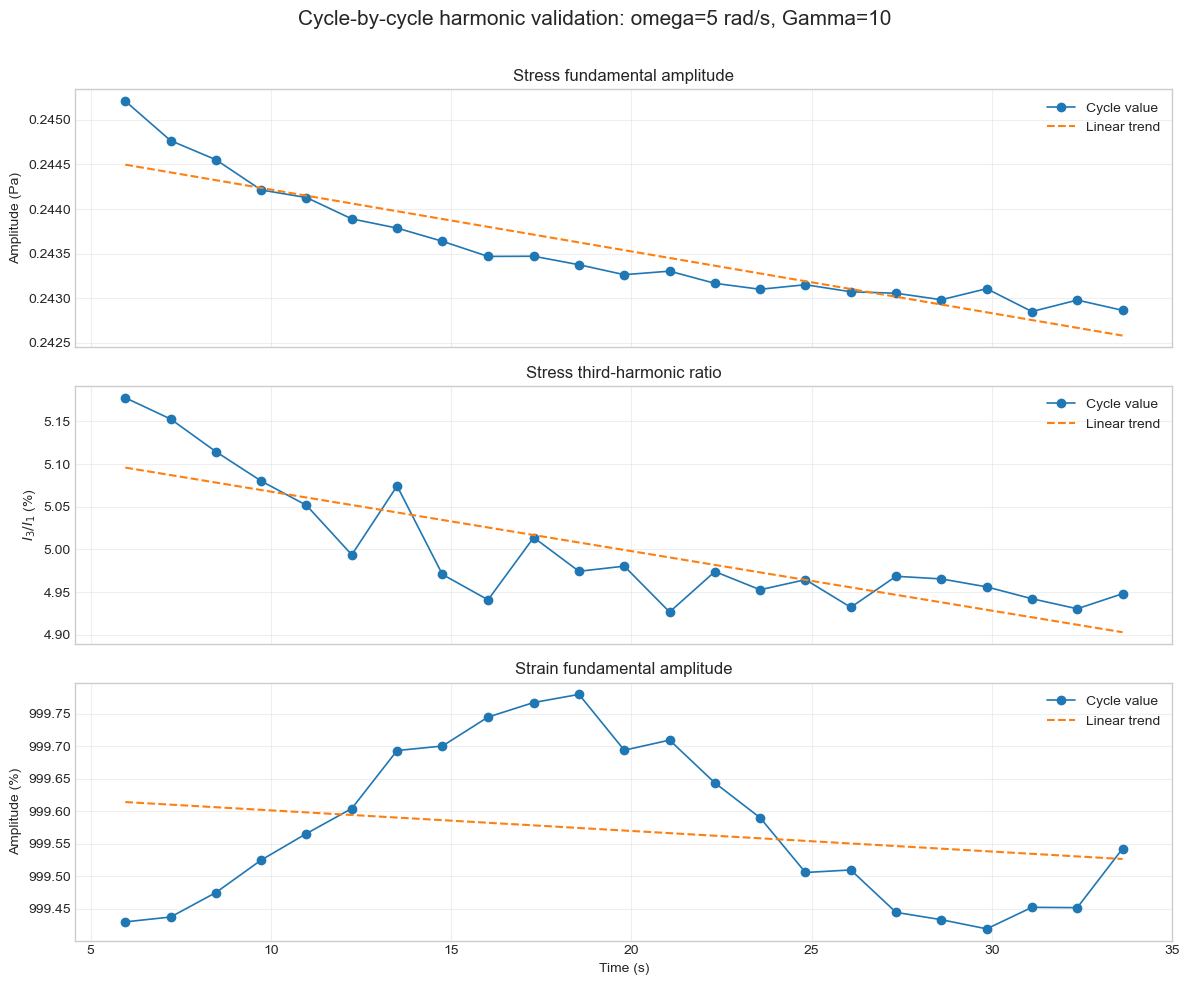

In [21]:
# Cycle-by-cycle harmonic validation

HARMONIC_ORDERS = [1, 3, 5, 7, 9]

cycle_harmonic_rows = []

for cycle_number, peak_position in enumerate(
    range(
        dwt_start_peak_position,
        dwt_end_peak_position,
    ),
    start=1,
):
    cycle_start_index = dwt_peak_indices[peak_position]
    cycle_end_index = dwt_peak_indices[peak_position + 1]

    cycle_time_s = stft_uniform_time_s[
        cycle_start_index:cycle_end_index
    ]

    cycle_stress_pa = stft_uniform_stress_pa[
        cycle_start_index:cycle_end_index
    ]

    cycle_strain_pct = stft_uniform_strain_pct[
        cycle_start_index:cycle_end_index
    ]

    local_time_s = cycle_time_s - cycle_time_s[0]

    design_columns = [np.ones_like(local_time_s)]

    for harmonic_order in HARMONIC_ORDERS:
        harmonic_frequency_hz = (
            harmonic_order * stft_fundamental_hz
        )

        design_columns.append(
            np.sin(
                2
                * np.pi
                * harmonic_frequency_hz
                * local_time_s
            )
        )

        design_columns.append(
            np.cos(
                2
                * np.pi
                * harmonic_frequency_hz
                * local_time_s
            )
        )

    design_matrix = np.column_stack(design_columns)

    stress_parameters = np.linalg.lstsq(
        design_matrix,
        cycle_stress_pa,
        rcond=None,
    )[0]

    strain_parameters = np.linalg.lstsq(
        design_matrix,
        cycle_strain_pct,
        rcond=None,
    )[0]

    stress_amplitudes = {}
    strain_amplitudes = {}

    for harmonic_index, harmonic_order in enumerate(
        HARMONIC_ORDERS
    ):
        sine_index = 1 + 2 * harmonic_index
        cosine_index = sine_index + 1

        stress_amplitudes[harmonic_order] = np.hypot(
            stress_parameters[sine_index],
            stress_parameters[cosine_index],
        )

        strain_amplitudes[harmonic_order] = np.hypot(
            strain_parameters[sine_index],
            strain_parameters[cosine_index],
        )

    cycle_harmonic_rows.append(
        {
            "cycle": cycle_number,
            "centre_time_s": np.mean(cycle_time_s),
            "stress_I1_pa": stress_amplitudes[1],
            "stress_I3_I1_pct": (
                100
                * stress_amplitudes[3]
                / stress_amplitudes[1]
            ),
            "stress_I5_I1_pct": (
                100
                * stress_amplitudes[5]
                / stress_amplitudes[1]
            ),
            "strain_I1_pct": strain_amplitudes[1],
            "strain_I3_I1_pct": (
                100
                * strain_amplitudes[3]
                / strain_amplitudes[1]
            ),
        }
    )

cycle_harmonic_results = pd.DataFrame(
    cycle_harmonic_rows
)


def summarise_cycle_feature(
    column_name,
    feature_name,
    unit,
):
    time_values = cycle_harmonic_results[
        "centre_time_s"
    ].to_numpy()

    feature_values = cycle_harmonic_results[
        column_name
    ].to_numpy()

    slope, intercept = np.polyfit(
        time_values,
        feature_values,
        1,
    )

    fitted_first_value = (
        slope * time_values[0] + intercept
    )

    fitted_last_value = (
        slope * time_values[-1] + intercept
    )

    fitted_change_pct = (
        100
        * (fitted_last_value - fitted_first_value)
        / fitted_first_value
    )

    return {
        "feature": feature_name,
        "unit": unit,
        "mean": np.mean(feature_values),
        "coefficient_of_variation_pct": (
            100
            * np.std(feature_values, ddof=1)
            / np.mean(feature_values)
        ),
        "fitted_first_to_last_change_pct": (
            fitted_change_pct
        ),
    }


cycle_harmonic_summary = pd.DataFrame(
    [
        summarise_cycle_feature(
            "stress_I1_pa",
            "Stress fundamental amplitude",
            "Pa",
        ),
        summarise_cycle_feature(
            "stress_I3_I1_pct",
            "Stress third-harmonic ratio",
            "%",
        ),
        summarise_cycle_feature(
            "stress_I5_I1_pct",
            "Stress fifth-harmonic ratio",
            "%",
        ),
        summarise_cycle_feature(
            "strain_I1_pct",
            "Strain fundamental amplitude",
            "%",
        ),
    ]
)

print(
    f"Number of analysed cycles: "
    f"{len(cycle_harmonic_results)}"
)

display(
    cycle_harmonic_summary.round(
        {
            "mean": 6,
            "coefficient_of_variation_pct": 3,
            "fitted_first_to_last_change_pct": 3,
        }
    )
)

# Plot cycle-by-cycle harmonic features
plot_features = [
    (
        "stress_I1_pa",
        "Stress fundamental amplitude",
        "Amplitude (Pa)",
    ),
    (
        "stress_I3_I1_pct",
        "Stress third-harmonic ratio",
        r"$I_3/I_1$ (%)",
    ),
    (
        "strain_I1_pct",
        "Strain fundamental amplitude",
        "Amplitude (%)",
    ),
]

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(12, 10),
    sharex=True,
)

time_values = cycle_harmonic_results[
    "centre_time_s"
].to_numpy()

for ax, (
    column_name,
    title,
    y_label,
) in zip(axes, plot_features):
    feature_values = cycle_harmonic_results[
        column_name
    ].to_numpy()

    slope, intercept = np.polyfit(
        time_values,
        feature_values,
        1,
    )

    fitted_values = slope * time_values + intercept

    ax.plot(
        time_values,
        feature_values,
        marker="o",
        linewidth=1.2,
        label="Cycle value",
    )

    ax.plot(
        time_values,
        fitted_values,
        linestyle="--",
        linewidth=1.5,
        label="Linear trend",
    )

    ax.set_title(title)
    ax.set_ylabel(y_label)
    ax.legend()
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel("Time (s)")

fig.suptitle(
    "Cycle-by-cycle harmonic validation: "
    "omega=5 rad/s, Gamma=10",
    fontsize=15,
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

Cycles in each comparison window: 5
Early cycle range: 1–5
Late cycle range: 19–23


,feature,unit,early_mean,late_mean,late_vs_early_change_pct,early_cv_pct,late_cv_pct
0,Stress fundamental amplitude,Pa,0.244575,0.242955,-0.662,0.180,0.043
1,Stress third-harmonic ratio,%,5.115343,4.948450,-3.263,1.005,0.269
2,Stress fifth-harmonic ratio,%,1.803221,1.747936,-3.066,2.569,1.486
3,Strain fundamental amplitude,%,999.486673,999.459814,-0.003,0.006,0.005


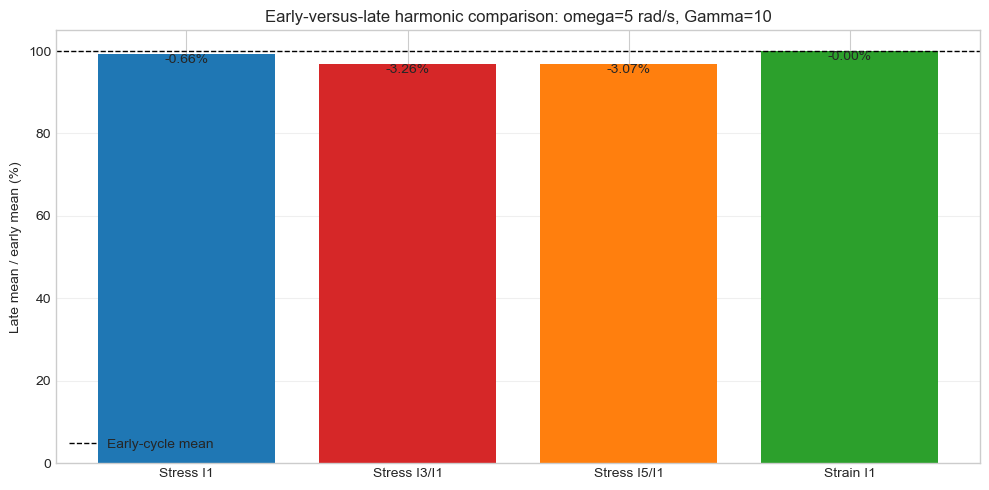

In [22]:
# Compare early and late cycle averages

NUMBER_OF_CYCLES_PER_WINDOW = 5

if len(cycle_harmonic_results) < (
    2 * NUMBER_OF_CYCLES_PER_WINDOW
):
    raise ValueError(
        "Not enough cycles for early-versus-late comparison."
    )

early_cycles = cycle_harmonic_results.head(
    NUMBER_OF_CYCLES_PER_WINDOW
)

late_cycles = cycle_harmonic_results.tail(
    NUMBER_OF_CYCLES_PER_WINDOW
)

comparison_features = {
    "stress_I1_pa": (
        "Stress fundamental amplitude",
        "Pa",
    ),
    "stress_I3_I1_pct": (
        "Stress third-harmonic ratio",
        "%",
    ),
    "stress_I5_I1_pct": (
        "Stress fifth-harmonic ratio",
        "%",
    ),
    "strain_I1_pct": (
        "Strain fundamental amplitude",
        "%",
    ),
}

early_late_rows = []

for column_name, (
    feature_name,
    unit,
) in comparison_features.items():
    early_values = early_cycles[column_name].to_numpy()
    late_values = late_cycles[column_name].to_numpy()

    early_mean = np.mean(early_values)
    late_mean = np.mean(late_values)

    early_late_rows.append(
        {
            "feature": feature_name,
            "unit": unit,
            "early_mean": early_mean,
            "late_mean": late_mean,
            "late_vs_early_change_pct": (
                100
                * (late_mean - early_mean)
                / early_mean
            ),
            "early_cv_pct": (
                100
                * np.std(early_values, ddof=1)
                / early_mean
            ),
            "late_cv_pct": (
                100
                * np.std(late_values, ddof=1)
                / late_mean
            ),
        }
    )

early_late_comparison = pd.DataFrame(
    early_late_rows
)

print(
    f"Cycles in each comparison window: "
    f"{NUMBER_OF_CYCLES_PER_WINDOW}"
)

print(
    "Early cycle range: "
    f"{early_cycles['cycle'].iloc[0]}–"
    f"{early_cycles['cycle'].iloc[-1]}"
)

print(
    "Late cycle range: "
    f"{late_cycles['cycle'].iloc[0]}–"
    f"{late_cycles['cycle'].iloc[-1]}"
)

display(
    early_late_comparison.round(
        {
            "early_mean": 6,
            "late_mean": 6,
            "late_vs_early_change_pct": 3,
            "early_cv_pct": 3,
            "late_cv_pct": 3,
        }
    )
)

# Plot late values relative to early values
normalised_late_values = (
    100
    * early_late_comparison["late_mean"]
    / early_late_comparison["early_mean"]
)

short_feature_names = [
    "Stress I1",
    "Stress I3/I1",
    "Stress I5/I1",
    "Strain I1",
]

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.bar(
    short_feature_names,
    normalised_late_values,
    color=[
        "tab:blue",
        "tab:red",
        "tab:orange",
        "tab:green",
    ],
)

ax.axhline(
    100,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Early-cycle mean",
)

for bar, value in zip(
    bars,
    normalised_late_values,
):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value - 100:+.2f}%",
        ha="center",
        va="top" if value < 100 else "bottom",
    )

ax.set_ylabel("Late mean / early mean (%)")
ax.set_title(
    "Early-versus-late harmonic comparison: "
    "omega=5 rad/s, Gamma=10"
)
ax.legend()
ax.grid(True, axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

,condition,strain_amplitude,cycles_analysed,stress_I1_change_pct,stress_I3_I1_change_pct,stress_I5_I1_change_pct,strain_I1_change_pct
0,LAOS omega=5 Gamma=0.5,0.5,23,-0.154,37.849,-1.008,0.002
1,LAOS omega=5 Gamma=1.0,1.0,23,-3.443,24.496,1.083,-0.003
2,LAOS omega=5 Gamma=5,5.0,23,-1.142,-5.401,-5.468,-0.006
3,LAOS omega=5 Gamma=10,10.0,23,-0.663,-3.365,-3.533,-0.004
4,LAOS omega=5 Gamma=50,50.0,23,0.005,-0.386,-0.315,-0.004
5,LAOS omega=5 Gamma=100,100.0,23,-0.123,-1.349,-0.098,0.001


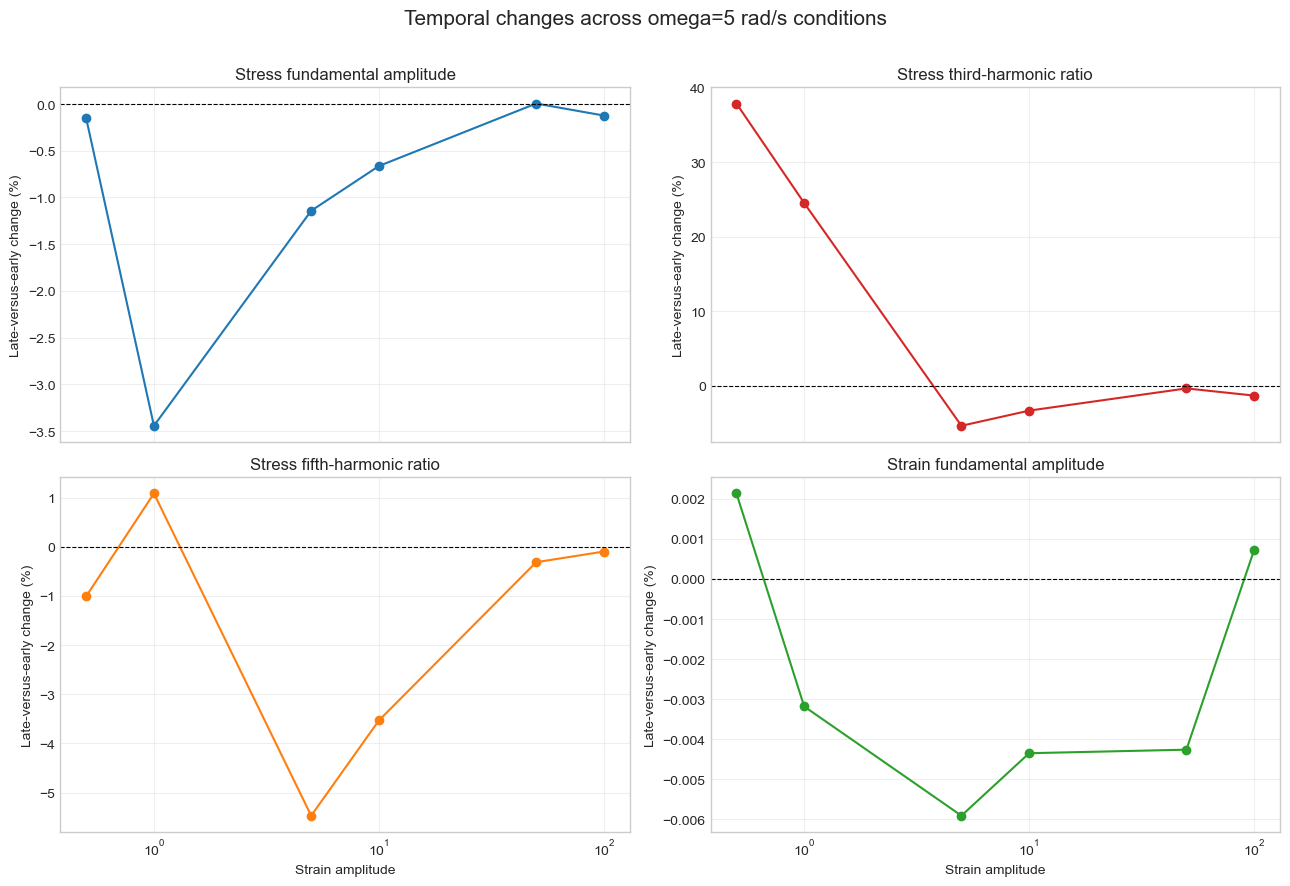

In [23]:
# Temporal change across all omega=5 conditions

import re

BATCH_OMEGA_RAD_S = 5.0
BATCH_BOUNDARY_CYCLES = 4
BATCH_COMPARISON_CYCLES = 5
BATCH_HARMONIC_ORDERS = [1, 3, 5, 7, 9]


def parse_laos_condition(condition_name):
    omega_match = re.search(
        r"omega\s*=\s*([0-9]+(?:\.[0-9]+)?)",
        condition_name,
        flags=re.IGNORECASE,
    )

    gamma_match = re.search(
        r"Gamma\s*=\s*([0-9]+(?:\.[0-9]+)?)",
        condition_name,
        flags=re.IGNORECASE,
    )

    if omega_match is None or gamma_match is None:
        raise ValueError(
            f"Cannot parse condition: {condition_name}"
        )

    return (
        float(omega_match.group(1)),
        float(gamma_match.group(1)),
    )


def calculate_harmonic_amplitudes(
    time_s,
    signal,
    fundamental_frequency_hz,
):
    local_time_s = time_s - time_s[0]
    design_columns = [np.ones_like(local_time_s)]

    for harmonic_order in BATCH_HARMONIC_ORDERS:
        harmonic_frequency_hz = (
            harmonic_order * fundamental_frequency_hz
        )

        design_columns.append(
            np.sin(
                2
                * np.pi
                * harmonic_frequency_hz
                * local_time_s
            )
        )

        design_columns.append(
            np.cos(
                2
                * np.pi
                * harmonic_frequency_hz
                * local_time_s
            )
        )

    design_matrix = np.column_stack(design_columns)

    parameters = np.linalg.lstsq(
        design_matrix,
        signal,
        rcond=None,
    )[0]

    amplitudes = {}

    for harmonic_index, harmonic_order in enumerate(
        BATCH_HARMONIC_ORDERS
    ):
        sine_index = 1 + 2 * harmonic_index
        cosine_index = sine_index + 1

        amplitudes[harmonic_order] = np.hypot(
            parameters[sine_index],
            parameters[cosine_index],
        )

    return amplitudes


def percentage_change(early_values, late_values):
    early_mean = np.mean(early_values)
    late_mean = np.mean(late_values)

    return 100 * (late_mean - early_mean) / early_mean


omega_5_conditions = []

for condition_name in laos_data["condition"].drop_duplicates():
    omega_rad_s, gamma = parse_laos_condition(
        condition_name
    )

    if np.isclose(omega_rad_s, BATCH_OMEGA_RAD_S):
        omega_5_conditions.append(
            (condition_name, gamma)
        )

omega_5_conditions.sort(key=lambda item: item[1])

batch_temporal_rows = []

for condition_name, gamma in omega_5_conditions:
    condition_data = (
        laos_data[
            laos_data["condition"] == condition_name
        ]
        .sort_values("time_s")
        .copy()
    )

    measured_time_s = pd.to_numeric(
        condition_data["time_s"],
        errors="coerce",
    ).to_numpy()

    measured_stress_pa = pd.to_numeric(
        condition_data["stress_pa"],
        errors="coerce",
    ).to_numpy()

    measured_strain_pct = pd.to_numeric(
        condition_data["strain_pct"],
        errors="coerce",
    ).to_numpy()

    valid_mask = (
        np.isfinite(measured_time_s)
        & np.isfinite(measured_stress_pa)
        & np.isfinite(measured_strain_pct)
    )

    measured_time_s = measured_time_s[valid_mask]
    measured_stress_pa = measured_stress_pa[valid_mask]
    measured_strain_pct = measured_strain_pct[valid_mask]

    unique_time_s, unique_indices = np.unique(
        measured_time_s,
        return_index=True,
    )

    measured_stress_pa = measured_stress_pa[
        unique_indices
    ]

    measured_strain_pct = measured_strain_pct[
        unique_indices
    ]

    median_dt_s = np.median(np.diff(unique_time_s))

    number_of_uniform_points = (
        int(
            np.round(
                (unique_time_s[-1] - unique_time_s[0])
                / median_dt_s
            )
        )
        + 1
    )

    uniform_time_s = np.linspace(
        unique_time_s[0],
        unique_time_s[-1],
        number_of_uniform_points,
    )

    uniform_stress_pa = np.interp(
        uniform_time_s,
        unique_time_s,
        measured_stress_pa,
    )

    uniform_strain_pct = np.interp(
        uniform_time_s,
        unique_time_s,
        measured_strain_pct,
    )

    uniform_dt_s = np.median(
        np.diff(uniform_time_s)
    )

    sampling_frequency_hz = 1 / uniform_dt_s

    fundamental_frequency_hz = (
        BATCH_OMEGA_RAD_S / (2 * np.pi)
    )

    samples_per_cycle = (
        sampling_frequency_hz
        / fundamental_frequency_hz
    )

    peak_indices, _ = find_peaks(
        uniform_strain_pct,
        distance=max(
            1,
            int(0.8 * samples_per_cycle),
        ),
        prominence=0.5 * np.std(
            uniform_strain_pct
        ),
    )

    minimum_required_peaks = (
        2 * BATCH_BOUNDARY_CYCLES
        + 2 * BATCH_COMPARISON_CYCLES
        + 1
    )

    if len(peak_indices) < minimum_required_peaks:
        raise ValueError(
            f"Not enough cycles for {condition_name}"
        )

    start_peak_position = BATCH_BOUNDARY_CYCLES

    end_peak_position = (
        len(peak_indices)
        - BATCH_BOUNDARY_CYCLES
        - 1
    )

    cycle_rows = []

    for peak_position in range(
        start_peak_position,
        end_peak_position,
    ):
        cycle_start_index = peak_indices[
            peak_position
        ]

        cycle_end_index = peak_indices[
            peak_position + 1
        ]

        cycle_time_s = uniform_time_s[
            cycle_start_index:cycle_end_index
        ]

        cycle_stress_pa = uniform_stress_pa[
            cycle_start_index:cycle_end_index
        ]

        cycle_strain_pct = uniform_strain_pct[
            cycle_start_index:cycle_end_index
        ]

        stress_amplitudes = (
            calculate_harmonic_amplitudes(
                cycle_time_s,
                cycle_stress_pa,
                fundamental_frequency_hz,
            )
        )

        strain_amplitudes = (
            calculate_harmonic_amplitudes(
                cycle_time_s,
                cycle_strain_pct,
                fundamental_frequency_hz,
            )
        )

        cycle_rows.append(
            {
                "stress_I1_pa": stress_amplitudes[1],
                "stress_I3_I1_pct": (
                    100
                    * stress_amplitudes[3]
                    / stress_amplitudes[1]
                ),
                "stress_I5_I1_pct": (
                    100
                    * stress_amplitudes[5]
                    / stress_amplitudes[1]
                ),
                "strain_I1_pct": strain_amplitudes[1],
            }
        )

    condition_cycle_results = pd.DataFrame(
        cycle_rows
    )

    early_results = condition_cycle_results.head(
        BATCH_COMPARISON_CYCLES
    )

    late_results = condition_cycle_results.tail(
        BATCH_COMPARISON_CYCLES
    )

    batch_temporal_rows.append(
        {
            "condition": condition_name,
            "strain_amplitude": gamma,
            "cycles_analysed": len(
                condition_cycle_results
            ),
            "stress_I1_change_pct": percentage_change(
                early_results["stress_I1_pa"],
                late_results["stress_I1_pa"],
            ),
            "stress_I3_I1_change_pct": percentage_change(
                early_results["stress_I3_I1_pct"],
                late_results["stress_I3_I1_pct"],
            ),
            "stress_I5_I1_change_pct": percentage_change(
                early_results["stress_I5_I1_pct"],
                late_results["stress_I5_I1_pct"],
            ),
            "strain_I1_change_pct": percentage_change(
                early_results["strain_I1_pct"],
                late_results["strain_I1_pct"],
            ),
        }
    )

omega_5_temporal_summary = pd.DataFrame(
    batch_temporal_rows
).sort_values("strain_amplitude")

display(
    omega_5_temporal_summary.round(
        {
            "strain_amplitude": 3,
            "stress_I1_change_pct": 3,
            "stress_I3_I1_change_pct": 3,
            "stress_I5_I1_change_pct": 3,
            "strain_I1_change_pct": 3,
        }
    )
)

# Plot temporal changes across strain amplitudes
plot_definitions = [
    (
        "stress_I1_change_pct",
        "Stress fundamental amplitude",
        "tab:blue",
    ),
    (
        "stress_I3_I1_change_pct",
        "Stress third-harmonic ratio",
        "tab:red",
    ),
    (
        "stress_I5_I1_change_pct",
        "Stress fifth-harmonic ratio",
        "tab:orange",
    ),
    (
        "strain_I1_change_pct",
        "Strain fundamental amplitude",
        "tab:green",
    ),
]

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(13, 9),
    sharex=True,
)

for ax, (
    column_name,
    title,
    colour,
) in zip(axes.flat, plot_definitions):
    ax.plot(
        omega_5_temporal_summary[
            "strain_amplitude"
        ],
        omega_5_temporal_summary[column_name],
        marker="o",
        color=colour,
        linewidth=1.5,
    )

    ax.axhline(
        0,
        color="black",
        linestyle="--",
        linewidth=0.8,
    )

    ax.set_xscale("log")
    ax.set_title(title)
    ax.set_ylabel("Late-versus-early change (%)")
    ax.grid(True, alpha=0.3)

axes[1, 0].set_xlabel("Strain amplitude")
axes[1, 1].set_xlabel("Strain amplitude")

fig.suptitle(
    "Temporal changes across omega=5 rad/s conditions",
    fontsize=15,
)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

Absolute harmonic amplitudes


,strain_amplitude,early_I1_pa,late_I1_pa,early_I3_pa,late_I3_pa,I3_amplitude_change_pct
0,0.5,0.026725,0.026684,0.000369,0.000508,37.576
1,1.0,0.042560,0.041095,0.001748,0.002102,20.235
2,5.0,0.140813,0.139205,0.006879,0.006432,-6.490
3,10.0,0.244377,0.242756,0.012425,0.011927,-4.009
4,50.0,0.937365,0.937414,0.031544,0.031424,-0.381
5,100.0,1.752053,1.749891,0.040892,0.040291,-1.471


Third-harmonic ratios


,strain_amplitude,early_I3_I1_pct,late_I3_I1_pct,I3_I1_change_percentage_points,I3_I1_relative_change_pct,early_I3_I1_cv_pct,late_I3_I1_cv_pct
0,0.5,1.3806,1.9032,0.5225,37.849,23.810,11.565
1,1.0,4.1086,5.1151,1.0065,24.496,4.913,2.671
2,5.0,4.8844,4.6206,-0.2638,-5.401,3.313,2.045
3,10.0,5.0841,4.9130,-0.1711,-3.365,1.378,0.406
4,50.0,3.3652,3.3522,-0.0130,-0.386,0.584,0.206
5,100.0,2.3340,2.3025,-0.0315,-1.349,0.320,0.227


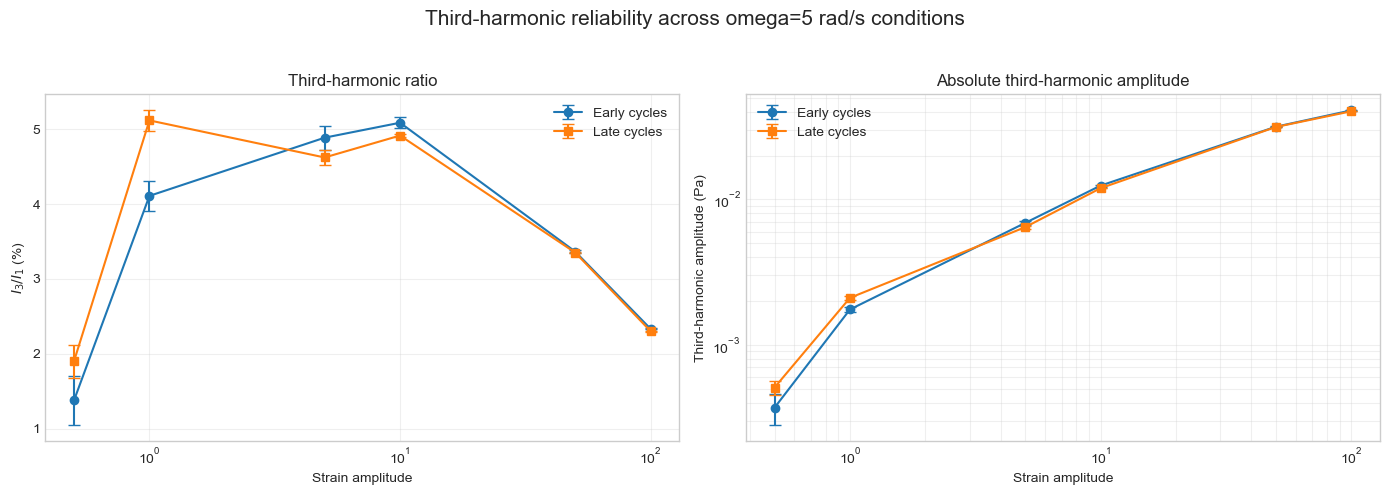

In [24]:
# Block 23: Absolute third-harmonic reliability check

def extract_cycle_harmonic_details(
    condition_name,
    omega_rad_s,
):
    condition_data = (
        laos_data[
            laos_data["condition"] == condition_name
        ]
        .sort_values("time_s")
        .copy()
    )

    measured_time_s = pd.to_numeric(
        condition_data["time_s"],
        errors="coerce",
    ).to_numpy()

    measured_stress_pa = pd.to_numeric(
        condition_data["stress_pa"],
        errors="coerce",
    ).to_numpy()

    measured_strain_pct = pd.to_numeric(
        condition_data["strain_pct"],
        errors="coerce",
    ).to_numpy()

    valid_mask = (
        np.isfinite(measured_time_s)
        & np.isfinite(measured_stress_pa)
        & np.isfinite(measured_strain_pct)
    )

    measured_time_s = measured_time_s[valid_mask]
    measured_stress_pa = measured_stress_pa[valid_mask]
    measured_strain_pct = measured_strain_pct[valid_mask]

    unique_time_s, unique_indices = np.unique(
        measured_time_s,
        return_index=True,
    )

    measured_stress_pa = measured_stress_pa[
        unique_indices
    ]

    measured_strain_pct = measured_strain_pct[
        unique_indices
    ]

    median_dt_s = np.median(
        np.diff(unique_time_s)
    )

    number_of_uniform_points = (
        int(
            np.round(
                (unique_time_s[-1] - unique_time_s[0])
                / median_dt_s
            )
        )
        + 1
    )

    uniform_time_s = np.linspace(
        unique_time_s[0],
        unique_time_s[-1],
        number_of_uniform_points,
    )

    uniform_stress_pa = np.interp(
        uniform_time_s,
        unique_time_s,
        measured_stress_pa,
    )

    uniform_strain_pct = np.interp(
        uniform_time_s,
        unique_time_s,
        measured_strain_pct,
    )

    uniform_dt_s = np.median(
        np.diff(uniform_time_s)
    )

    sampling_frequency_hz = 1 / uniform_dt_s
    fundamental_frequency_hz = omega_rad_s / (2 * np.pi)

    samples_per_cycle = (
        sampling_frequency_hz
        / fundamental_frequency_hz
    )

    peak_indices, _ = find_peaks(
        uniform_strain_pct,
        distance=max(
            1,
            int(0.8 * samples_per_cycle),
        ),
        prominence=0.5 * np.std(
            uniform_strain_pct
        ),
    )

    start_peak_position = BATCH_BOUNDARY_CYCLES

    end_peak_position = (
        len(peak_indices)
        - BATCH_BOUNDARY_CYCLES
        - 1
    )

    if end_peak_position <= start_peak_position:
        raise ValueError(
            f"Not enough interior cycles for {condition_name}"
        )

    cycle_rows = []

    for peak_position in range(
        start_peak_position,
        end_peak_position,
    ):
        cycle_start_index = peak_indices[
            peak_position
        ]

        cycle_end_index = peak_indices[
            peak_position + 1
        ]

        cycle_time_s = uniform_time_s[
            cycle_start_index:cycle_end_index
        ]

        cycle_stress_pa = uniform_stress_pa[
            cycle_start_index:cycle_end_index
        ]

        cycle_strain_pct = uniform_strain_pct[
            cycle_start_index:cycle_end_index
        ]

        stress_amplitudes = (
            calculate_harmonic_amplitudes(
                cycle_time_s,
                cycle_stress_pa,
                fundamental_frequency_hz,
            )
        )

        strain_amplitudes = (
            calculate_harmonic_amplitudes(
                cycle_time_s,
                cycle_strain_pct,
                fundamental_frequency_hz,
            )
        )

        cycle_rows.append(
            {
                "stress_I1_pa": stress_amplitudes[1],
                "stress_I3_pa": stress_amplitudes[3],
                "stress_I3_I1_pct": (
                    100
                    * stress_amplitudes[3]
                    / stress_amplitudes[1]
                ),
                "strain_I1_pct": strain_amplitudes[1],
            }
        )

    return pd.DataFrame(cycle_rows)


omega_5_cycle_details = {}
third_harmonic_rows = []

for condition_name, gamma in omega_5_conditions:
    condition_results = extract_cycle_harmonic_details(
        condition_name,
        BATCH_OMEGA_RAD_S,
    )

    omega_5_cycle_details[condition_name] = (
        condition_results
    )

    early_results = condition_results.head(
        BATCH_COMPARISON_CYCLES
    )

    late_results = condition_results.tail(
        BATCH_COMPARISON_CYCLES
    )

    early_I1_mean = early_results[
        "stress_I1_pa"
    ].mean()

    late_I1_mean = late_results[
        "stress_I1_pa"
    ].mean()

    early_I3_mean = early_results[
        "stress_I3_pa"
    ].mean()

    late_I3_mean = late_results[
        "stress_I3_pa"
    ].mean()

    early_ratio_mean = early_results[
        "stress_I3_I1_pct"
    ].mean()

    late_ratio_mean = late_results[
        "stress_I3_I1_pct"
    ].mean()

    early_ratio_sd = early_results[
        "stress_I3_I1_pct"
    ].std(ddof=1)

    late_ratio_sd = late_results[
        "stress_I3_I1_pct"
    ].std(ddof=1)

    early_I3_sd = early_results[
        "stress_I3_pa"
    ].std(ddof=1)

    late_I3_sd = late_results[
        "stress_I3_pa"
    ].std(ddof=1)

    third_harmonic_rows.append(
        {
            "condition": condition_name,
            "strain_amplitude": gamma,
            "early_I1_pa": early_I1_mean,
            "late_I1_pa": late_I1_mean,
            "early_I3_pa": early_I3_mean,
            "late_I3_pa": late_I3_mean,
            "I3_amplitude_change_pct": (
                100
                * (late_I3_mean - early_I3_mean)
                / early_I3_mean
            ),
            "early_I3_I1_pct": early_ratio_mean,
            "late_I3_I1_pct": late_ratio_mean,
            "I3_I1_change_percentage_points": (
                late_ratio_mean - early_ratio_mean
            ),
            "I3_I1_relative_change_pct": (
                100
                * (late_ratio_mean - early_ratio_mean)
                / early_ratio_mean
            ),
            "early_I3_I1_cv_pct": (
                100
                * early_ratio_sd
                / early_ratio_mean
            ),
            "late_I3_I1_cv_pct": (
                100
                * late_ratio_sd
                / late_ratio_mean
            ),
            "early_I3_sd_pa": early_I3_sd,
            "late_I3_sd_pa": late_I3_sd,
            "early_I3_I1_sd_pct": early_ratio_sd,
            "late_I3_I1_sd_pct": late_ratio_sd,
        }
    )

third_harmonic_reliability = pd.DataFrame(
    third_harmonic_rows
).sort_values("strain_amplitude")


# Display absolute harmonic amplitudes
amplitude_columns = [
    "strain_amplitude",
    "early_I1_pa",
    "late_I1_pa",
    "early_I3_pa",
    "late_I3_pa",
    "I3_amplitude_change_pct",
]

print("Absolute harmonic amplitudes")

display(
    third_harmonic_reliability[
        amplitude_columns
    ].round(
        {
            "strain_amplitude": 3,
            "early_I1_pa": 6,
            "late_I1_pa": 6,
            "early_I3_pa": 7,
            "late_I3_pa": 7,
            "I3_amplitude_change_pct": 3,
        }
    )
)


# Display third-harmonic ratios and variability
ratio_columns = [
    "strain_amplitude",
    "early_I3_I1_pct",
    "late_I3_I1_pct",
    "I3_I1_change_percentage_points",
    "I3_I1_relative_change_pct",
    "early_I3_I1_cv_pct",
    "late_I3_I1_cv_pct",
]

print("Third-harmonic ratios")

display(
    third_harmonic_reliability[
        ratio_columns
    ].round(
        {
            "strain_amplitude": 3,
            "early_I3_I1_pct": 4,
            "late_I3_I1_pct": 4,
            "I3_I1_change_percentage_points": 4,
            "I3_I1_relative_change_pct": 3,
            "early_I3_I1_cv_pct": 3,
            "late_I3_I1_cv_pct": 3,
        }
    )
)


# Plot early and late third-harmonic measurements
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(14, 5),
)

gamma_values = third_harmonic_reliability[
    "strain_amplitude"
]

axes[0].errorbar(
    gamma_values,
    third_harmonic_reliability[
        "early_I3_I1_pct"
    ],
    yerr=third_harmonic_reliability[
        "early_I3_I1_sd_pct"
    ],
    marker="o",
    capsize=4,
    label="Early cycles",
)

axes[0].errorbar(
    gamma_values,
    third_harmonic_reliability[
        "late_I3_I1_pct"
    ],
    yerr=third_harmonic_reliability[
        "late_I3_I1_sd_pct"
    ],
    marker="s",
    capsize=4,
    label="Late cycles",
)

axes[0].set_xscale("log")
axes[0].set_xlabel("Strain amplitude")
axes[0].set_ylabel(r"$I_3/I_1$ (%)")
axes[0].set_title("Third-harmonic ratio")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].errorbar(
    gamma_values,
    third_harmonic_reliability[
        "early_I3_pa"
    ],
    yerr=third_harmonic_reliability[
        "early_I3_sd_pa"
    ],
    marker="o",
    capsize=4,
    label="Early cycles",
)

axes[1].errorbar(
    gamma_values,
    third_harmonic_reliability[
        "late_I3_pa"
    ],
    yerr=third_harmonic_reliability[
        "late_I3_sd_pa"
    ],
    marker="s",
    capsize=4,
    label="Late cycles",
)

axes[1].set_xscale("log")
axes[1].set_yscale("log")
axes[1].set_xlabel("Strain amplitude")
axes[1].set_ylabel("Third-harmonic amplitude (Pa)")
axes[1].set_title("Absolute third-harmonic amplitude")
axes[1].legend()
axes[1].grid(True, which="both", alpha=0.3)

fig.suptitle(
    "Third-harmonic reliability across "
    "omega=5 rad/s conditions",
    fontsize=15,
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

,method,main_role,main_result,interpretation
0,FFT and harmonic regression,Quantify exact harmonic amplitudes,"Mean stress I3/I1 = 4.999% for omega=5 rad/s, ...",Provides the primary quantitative measure of n...
1,STFT,Track frequency content over time,Fundamental and third-harmonic bands remain vi...,Shows that harmonic content is slightly time-d...
2,CWT,Track multiscale temporal behaviour,The decreasing stress-harmonic trend remains a...,"Confirms the direction of temporal change, but..."
3,DWT,Measure energy across signal scales,98.53% in fundamental-scale bands; 1.20% in th...,The measured response is dominated by the fund...
4,Cycle-by-cycle Fourier analysis,Validate temporal harmonic changes,I3/I1 changes by -0.171 percentage points (-3....,Gamma=10 shows a small but consistent decrease...
5,Input stability check,Exclude changes in imposed strain,Strain I1 changes by -0.0043%,The observed stress changes are not caused by ...
6,Machine learning,Optional future prediction or classification,Not used in the current analysis,The current dataset and objectives are better ...


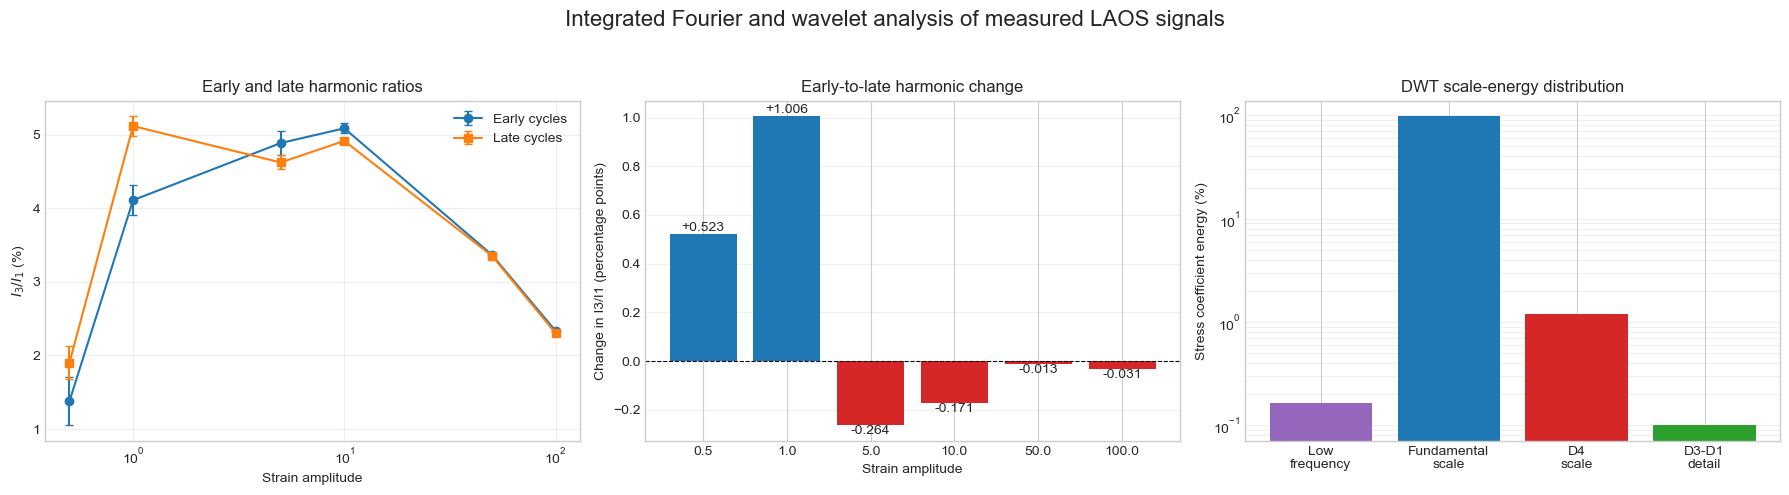

In [25]:
# Block 24: Final integrated summary

SELECTED_FINAL_GAMMA = 10.0

selected_reliability_row = (
    third_harmonic_reliability[
        np.isclose(
            third_harmonic_reliability[
                "strain_amplitude"
            ],
            SELECTED_FINAL_GAMMA,
        )
    ]
    .iloc[0]
)

selected_temporal_row = (
    omega_5_temporal_summary[
        np.isclose(
            omega_5_temporal_summary[
                "strain_amplitude"
            ],
            SELECTED_FINAL_GAMMA,
        )
    ]
    .iloc[0]
)

mean_third_harmonic_ratio = (
    cycle_harmonic_summary.loc[
        cycle_harmonic_summary["feature"]
        == "Stress third-harmonic ratio",
        "mean",
    ]
    .iloc[0]
)

fundamental_scale_energy = (
    dwt_group_energy_table.loc[
        dwt_group_energy_table["component"]
        == "Fundamental-scale component",
        "stress_energy_pct",
    ]
    .iloc[0]
)

third_harmonic_scale_energy = (
    dwt_group_energy_table.loc[
        dwt_group_energy_table["component"]
        == "Third-harmonic-scale component",
        "stress_energy_pct",
    ]
    .iloc[0]
)

high_frequency_energy = (
    dwt_group_energy_table.loc[
        dwt_group_energy_table["component"]
        == "High-frequency detail",
        "stress_energy_pct",
    ]
    .iloc[0]
)

final_method_summary = pd.DataFrame(
    [
        {
            "method": "FFT and harmonic regression",
            "main_role": "Quantify exact harmonic amplitudes",
            "main_result": (
                f"Mean stress I3/I1 = "
                f"{mean_third_harmonic_ratio:.3f}% "
                f"for omega=5 rad/s, Gamma=10"
            ),
            "interpretation": (
                "Provides the primary quantitative "
                "measure of nonlinear distortion"
            ),
        },
        {
            "method": "STFT",
            "main_role": "Track frequency content over time",
            "main_result": (
                "Fundamental and third-harmonic bands "
                "remain visible across the measurement"
            ),
            "interpretation": (
                "Shows that harmonic content is "
                "slightly time-dependent"
            ),
        },
        {
            "method": "CWT",
            "main_role": "Track multiscale temporal behaviour",
            "main_result": (
                "The decreasing stress-harmonic trend "
                "remains after boundary exclusion"
            ),
            "interpretation": (
                "Confirms the direction of temporal "
                "change, but the magnitude is "
                "boundary-sensitive"
            ),
        },
        {
            "method": "DWT",
            "main_role": "Measure energy across signal scales",
            "main_result": (
                f"{fundamental_scale_energy:.2f}% in "
                f"fundamental-scale bands; "
                f"{third_harmonic_scale_energy:.2f}% in "
                f"the D4 band; "
                f"{high_frequency_energy:.3f}% in "
                f"D3-D1"
            ),
            "interpretation": (
                "The measured response is dominated "
                "by the fundamental scale"
            ),
        },
        {
            "method": "Cycle-by-cycle Fourier analysis",
            "main_role": "Validate temporal harmonic changes",
            "main_result": (
                f"I3/I1 changes by "
                f"{selected_reliability_row['I3_I1_change_percentage_points']:+.3f} "
                f"percentage points "
                f"({selected_reliability_row['I3_I1_relative_change_pct']:+.2f}%)"
            ),
            "interpretation": (
                "Gamma=10 shows a small but consistent "
                "decrease in nonlinear response"
            ),
        },
        {
            "method": "Input stability check",
            "main_role": "Exclude changes in imposed strain",
            "main_result": (
                f"Strain I1 changes by "
                f"{selected_temporal_row['strain_I1_change_pct']:+.4f}%"
            ),
            "interpretation": (
                "The observed stress changes are not "
                "caused by a changing strain amplitude"
            ),
        },
        {
            "method": "Machine learning",
            "main_role": "Optional future prediction or classification",
            "main_result": "Not used in the current analysis",
            "interpretation": (
                "The current dataset and objectives "
                "are better served by interpretable "
                "signal-processing methods"
            ),
        },
    ]
)

display(final_method_summary)


# Create the final integrated figure
fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(18, 5),
)

gamma_values = third_harmonic_reliability[
    "strain_amplitude"
]

# Panel 1: Early and late third-harmonic ratios
axes[0].errorbar(
    gamma_values,
    third_harmonic_reliability[
        "early_I3_I1_pct"
    ],
    yerr=third_harmonic_reliability[
        "early_I3_I1_sd_pct"
    ],
    marker="o",
    capsize=3,
    label="Early cycles",
)

axes[0].errorbar(
    gamma_values,
    third_harmonic_reliability[
        "late_I3_I1_pct"
    ],
    yerr=third_harmonic_reliability[
        "late_I3_I1_sd_pct"
    ],
    marker="s",
    capsize=3,
    label="Late cycles",
)

axes[0].set_xscale("log")
axes[0].set_xlabel("Strain amplitude")
axes[0].set_ylabel(r"$I_3/I_1$ (%)")
axes[0].set_title("Early and late harmonic ratios")
axes[0].legend()
axes[0].grid(True, alpha=0.3)


# Panel 2: Absolute percentage-point changes
ratio_changes = third_harmonic_reliability[
    "I3_I1_change_percentage_points"
]

change_colours = [
    "tab:blue" if value >= 0 else "tab:red"
    for value in ratio_changes
]

bars = axes[1].bar(
    [
        str(value)
        for value in gamma_values
    ],
    ratio_changes,
    color=change_colours,
)

axes[1].axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=0.8,
)

for bar, value in zip(bars, ratio_changes):
    axes[1].text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:+.3f}",
        ha="center",
        va="bottom" if value >= 0 else "top",
    )

axes[1].set_xlabel("Strain amplitude")
axes[1].set_ylabel("Change in I3/I1 (percentage points)")
axes[1].set_title("Early-to-late harmonic change")
axes[1].grid(True, axis="y", alpha=0.3)


# Panel 3: DWT stress-energy distribution
dwt_short_names = [
    "Low\nfrequency",
    "Fundamental\nscale",
    "D4\nscale",
    "D3-D1\ndetail",
]

dwt_stress_energy = dwt_group_energy_table[
    "stress_energy_pct"
].to_numpy()

axes[2].bar(
    dwt_short_names,
    dwt_stress_energy,
    color=[
        "tab:purple",
        "tab:blue",
        "tab:red",
        "tab:green",
    ],
)

axes[2].set_yscale("log")
axes[2].set_ylabel("Stress coefficient energy (%)")
axes[2].set_title("DWT scale-energy distribution")
axes[2].grid(True, axis="y", which="both", alpha=0.3)

fig.suptitle(
    "Integrated Fourier and wavelet analysis "
    "of measured LAOS signals",
    fontsize=16,
)

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()
